# Obtaining raw data

In [2]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/PM25_Prediction


Create folder for the dataset

In [3]:
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "experiments",
    "figures"
]

# Check if any of the folders are missing
missing_folders = [f for f in folders if not (PROJECT_DIR / f).exists()]

if missing_folders:
    for folder in missing_folders:
        (PROJECT_DIR / folder).mkdir(
            parents=True,
            exist_ok=True
        )
    print("Created folder:", missing_folders)

print("Project folder ready:", PROJECT_DIR)

Project folder ready: /content/drive/MyDrive/PM25_Prediction


Download weather data

In [4]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 13.729852,
    "longitude": 100.536501,
    "start_date": "2021-04-30",
    "end_date": "2026-10-31",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "precipitation"
    ],
    "timezone": "Asia/Bangkok"
}

response = requests.get(
    url,
    params=params,
    timeout=120
)

response.raise_for_status()

data = response.json()

weather_df = pd.DataFrame(data["hourly"])

print(weather_df.head())
print(weather_df.shape)
print(weather_df.isnull().sum())

               time  temperature_2m  relative_humidity_2m  wind_speed_10m  \
0  2021-04-30T00:00            25.3                    92             2.4   
1  2021-04-30T01:00            25.3                    93             4.4   
2  2021-04-30T02:00            25.1                    94             4.3   
3  2021-04-30T03:00            24.8                    96             4.6   
4  2021-04-30T04:00            24.6                    97             4.9   

   precipitation  
0            0.4  
1            0.1  
2            0.1  
3            0.0  
4            0.0  
(48264, 5)
time                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
dtype: int64


In [5]:
weather_df = weather_df.rename(columns={
    "time": "datetime",
    "temperature_2m": "temperature",
    "relative_humidity_2m": "humidity",
    "wind_speed_10m": "wind_speed"
})

weather_df["datetime"] = (
    pd.to_datetime(weather_df["datetime"])
    .dt.tz_localize("Asia/Bangkok")
)

print(weather_df.head())
print(weather_df.dtypes)

                   datetime  temperature  humidity  wind_speed  precipitation
0 2021-04-30 00:00:00+07:00         25.3        92         2.4            0.4
1 2021-04-30 01:00:00+07:00         25.3        93         4.4            0.1
2 2021-04-30 02:00:00+07:00         25.1        94         4.3            0.1
3 2021-04-30 03:00:00+07:00         24.8        96         4.6            0.0
4 2021-04-30 04:00:00+07:00         24.6        97         4.9            0.0
datetime         datetime64[ns, Asia/Bangkok]
temperature                           float64
humidity                                int64
wind_speed                            float64
precipitation                         float64
dtype: object


In [6]:
assert len(weather_df) == 48264
assert weather_df["datetime"].is_unique
assert weather_df["datetime"].is_monotonic_increasing

assert (
    weather_df["datetime"].diff().dropna()
    == pd.Timedelta(hours=1)
).all()

print("Missing values:")
print(weather_df.isna().sum())

print("\nWeather units:")
print(data["hourly_units"])

print("\nFirst datetime:", weather_df["datetime"].min())
print("Last datetime:", weather_df["datetime"].max())

Missing values:
datetime         0
temperature      0
humidity         0
wind_speed       0
precipitation    0
dtype: int64

Weather units:
{'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'wind_speed_10m': 'km/h', 'precipitation': 'mm'}

First datetime: 2021-04-30 00:00:00+07:00
Last datetime: 2026-10-31 23:00:00+07:00


In [7]:
output = (
    PROJECT_DIR
    / "data/raw/weather_hourly_chula_2021_2026.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

weather_df.to_csv(output, index=False)

print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/data/raw/weather_hourly_chula_2021_2026.csv


Download PM2.5 data

In [8]:
import requests
from google.colab import userdata

API_KEY = userdata.get("OPENAQ_API_KEY")

BASE_URL = "https://api.openaq.org/v3"
HEADERS = {"X-API-Key": API_KEY}

response = requests.get(
    f"{BASE_URL}/locations/5545/sensors",
    headers=HEADERS,
    timeout=30
)
response.raise_for_status()

sensors = response.json()["results"]

for sensor in sensors:
    print(
        "Sensor ID:", sensor["id"],
        "| Parameter:", sensor["parameter"]["name"],
        "| Unit:", sensor["parameter"]["units"]
    )

Sensor ID: 22728 | Parameter: no2 | Unit: ppm
Sensor ID: 22726 | Parameter: pm10 | Unit: µg/m³
Sensor ID: 14630 | Parameter: o3 | Unit: ppm
Sensor ID: 1304222 | Parameter: pm25 | Unit: µg/m³
Sensor ID: 20306 | Parameter: so2 | Unit: ppm
Sensor ID: 22727 | Parameter: co | Unit: ppm


In [9]:
import requests
import pandas as pd
import time

from tqdm.auto import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

pm25_sensors = [
    s for s in sensors
    if s["parameter"]["name"].lower() == "pm25"
]

assert pm25_sensors, "No PM2.5 sensor found"

SENSOR_ID = pm25_sensors[0]["id"]

START_DATE = pd.Timestamp("2021-04-30", tz="Asia/Bangkok")

# Exclusive end boundary, including all of October 31
END_DATE = pd.Timestamp("2026-11-01", tz="Asia/Bangkok")

# Configure automatic retries
session = requests.Session()
session.headers.update(HEADERS)

retry = Retry(
    total=5,
    backoff_factor=2,
    status_forcelist=[408, 429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session.mount(
    "https://",
    HTTPAdapter(max_retries=retry)
)

# Generate monthly download periods
months = pd.date_range(
    START_DATE.replace(day=1),
    END_DATE,
    freq="MS"
)

all_records = []

for month in tqdm(months, desc="Downloading hourly PM2.5"):

    start = max(month, START_DATE)

    end = min(
        month + pd.offsets.MonthBegin(1),
        END_DATE
    )

    if start >= end:
        continue

    page = 1
    monthly_count = 0

    while True:

        response = session.get(
            f"{BASE_URL}/sensors/{SENSOR_ID}/hours",
            params={
                "datetime_from": start.isoformat(),
                "datetime_to": end.isoformat(),
                "limit": 1000,
                "page": page
            },
            timeout=120
        )

        response.raise_for_status()

        batch = response.json()["results"]

        all_records.extend(batch)
        monthly_count += len(batch)

        time.sleep(1.2)

        if len(batch) < 1000:
            break

        page += 1

    tqdm.write(
        f"{start.strftime('%Y-%m')}: "
        f"{monthly_count} records"
    )

print("\nTotal hourly records:", len(all_records))

2021-04: 18 records
2021-05: 290 records
2021-06: 370 records
2021-07: 268 records
2021-08: 477 records
2021-09: 659 records
2021-10: 718 records
2021-11: 614 records
2021-12: 698 records
2022-01: 676 records
2022-02: 609 records
2022-03: 603 records
2022-04: 691 records
2022-05: 673 records
2022-06: 690 records
2022-07: 699 records
2022-08: 699 records
2022-09: 600 records
2022-10: 719 records
2022-11: 695 records
2022-12: 523 records
2023-01: 22 records
2023-02: 48 records
2023-03: 272 records
2023-04: 650 records
2023-05: 717 records
2023-06: 706 records
2023-07: 669 records
2023-08: 699 records
2023-09: 705 records
2023-10: 626 records
2023-11: 687 records
2023-12: 605 records
2024-01: 695 records
2024-02: 630 records
2024-03: 707 records
2024-04: 694 records
2024-05: 703 records
2024-06: 673 records
2024-07: 602 records
2024-08: 593 records
2024-09: 520 records
2024-10: 578 records
2024-11: 452 records
2024-12: 450 records
2025-01: 503 records
2025-02: 608 records
2025-03: 671 rec

In [10]:
import numpy as np

rows = []

for record in all_records:

    period = record.get("period") or {}
    dt_from = period.get("datetimeFrom") or {}

    rows.append({
        "datetime": dt_from.get("local"),
        "pm25": record.get("value")
    })

pm25_hourly = pd.DataFrame(
    rows,
    columns=["datetime", "pm25"]
)

pm25_hourly["datetime"] = (
    pd.to_datetime(pm25_hourly["datetime"], utc=True)
    .dt.tz_convert("Asia/Bangkok")
)

pm25_hourly["pm25"] = pd.to_numeric(
    pm25_hourly["pm25"],
    errors="coerce"
)

# Restrict to the exact requested period
pm25_hourly = pm25_hourly[
    (pm25_hourly["datetime"] >= START_DATE) &
    (pm25_hourly["datetime"] < END_DATE)
]

# Remove exact duplicate records
pm25_hourly = pm25_hourly.drop_duplicates()

# Check for conflicting measurements
assert pm25_hourly["datetime"].is_unique, \
    "Conflicting hourly measurements found"

pm25_hourly = (
    pm25_hourly
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Total records:", len(pm25_hourly))
print("First measurement:", pm25_hourly["datetime"].min())
print("Last measurement:", pm25_hourly["datetime"].max())

print("\nMissing values:")
print(pm25_hourly.isna().sum())

print("\nNegative values:")
print((pm25_hourly["pm25"] < 0).sum())

print("\nFirst 10 records:")
print(pm25_hourly.head(10))

Total records: 37440
First measurement: 2021-04-30 02:00:00+07:00
Last measurement: 2026-10-31 23:00:00+07:00

Missing values:
datetime    0
pm25        0
dtype: int64

Negative values:
0

First 10 records:
                   datetime  pm25
0 2021-04-30 02:00:00+07:00  19.0
1 2021-04-30 03:00:00+07:00  19.0
2 2021-04-30 04:00:00+07:00  20.0
3 2021-04-30 05:00:00+07:00  20.0
4 2021-04-30 06:00:00+07:00  21.0
5 2021-04-30 07:00:00+07:00  21.0
6 2021-04-30 08:00:00+07:00  21.0
7 2021-04-30 09:00:00+07:00  21.0
8 2021-04-30 11:00:00+07:00  21.0
9 2021-04-30 12:00:00+07:00  20.0


In [11]:
expected_hours = pd.date_range(
    START_DATE,
    END_DATE,
    freq="h",
    inclusive="left"
)

valid_mask = (
    np.isfinite(pm25_hourly["pm25"]) &
    (pm25_hourly["pm25"] >= 0)
)

observed_hours = pd.DatetimeIndex(
    pm25_hourly.loc[valid_mask, "datetime"]
)

missing_hours = expected_hours.difference(
    observed_hours
)

print("Expected hours:", len(expected_hours))

print("Available valid hours:",
      len(expected_hours.intersection(observed_hours)))

print("Missing hours:", len(missing_hours))

print(
    f"Completeness: "
    f"{(1 - len(missing_hours) / len(expected_hours)) * 100:.2f}%"
)

Expected hours: 48264
Available valid hours: 37440
Missing hours: 10824
Completeness: 77.57%


In [12]:
output = (
    PROJECT_DIR
    / "data/raw/pm25_hourly_openaq.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

pm25_hourly.to_csv(output, index=False)

print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/data/raw/pm25_hourly_openaq.csv


In [13]:
expected_hours = pd.date_range(
    start="2021-04-30 00:00:00",
    end="2026-10-31 23:00:00",
    freq="h",
    tz="Asia/Bangkok"
)

hourly_check = (
    pm25_hourly
    .set_index("datetime")
    .reindex(expected_hours)
)

hourly_check.index.name = "datetime"

yearly_summary = (
    hourly_check
    .groupby(hourly_check.index.year)["pm25"]
    .agg(
        expected_hours="size",
        observed_hours="count"
    )
)

yearly_summary["missing_hours"] = (
    yearly_summary["expected_hours"]
    - yearly_summary["observed_hours"]
)

yearly_summary["completeness"] = (
    yearly_summary["observed_hours"]
    / yearly_summary["expected_hours"]
    * 100
)

display(yearly_summary.round(2))

,expected_hours,observed_hours,missing_hours,completeness
datetime,,,,
2021,5904,4112,1792,69.65
2022,8760,7877,883,89.92
2023,8760,6406,2354,73.13
2024,8784,7297,1487,83.07
2025,8760,5427,3333,61.95
2026,7296,6321,975,86.64


In [14]:
missing = hourly_check["pm25"].isna()

groups = missing.ne(
    missing.shift()
).cumsum()

missing_periods = (
    hourly_check[missing]
    .reset_index()
    .groupby(groups[missing].to_numpy())
    .agg(
        start=("datetime", "min"),
        end=("datetime", "max"),
        hours=("datetime", "size")
    )
    .sort_values("hours", ascending=False)
)

missing_periods["days"] = (
    missing_periods["hours"] / 24
)

display(missing_periods.head(15))

,start,end,hours,days
3129,2025-07-01 04:00:00+07:00,2025-08-25 14:00:00+07:00,1331,55.458333
1147,2023-01-02 00:00:00+07:00,2023-02-14 07:00:00+07:00,1040,43.333333
3243,2025-10-10 21:00:00+07:00,2025-11-18 22:00:00+07:00,938,39.083333
1149,2023-02-16 08:00:00+07:00,2023-03-19 07:00:00+07:00,744,31.000000
3643,2026-07-02 09:00:00+07:00,2026-07-30 00:00:00+07:00,664,27.666667
3047,2025-04-25 17:00:00+07:00,2025-05-07 20:00:00+07:00,292,12.166667
629,2021-07-25 16:00:00+07:00,2021-08-04 02:00:00+07:00,227,9.458333
1139,2022-12-08 02:00:00+07:00,2022-12-16 05:00:00+07:00,196,8.166667
3195,2025-09-21 16:00:00+07:00,2025-09-24 11:00:00+07:00,68,2.833333
519,2021-07-10 09:00:00+07:00,2021-07-12 23:00:00+07:00,63,2.625000


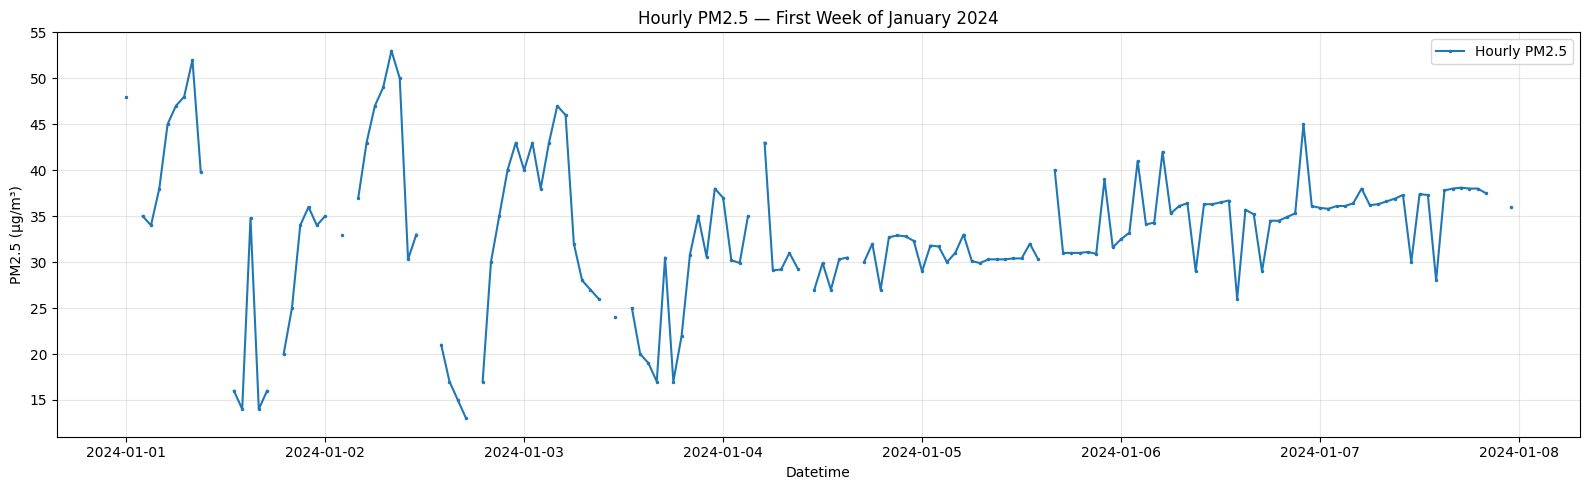

In [15]:
import matplotlib.pyplot as plt

sample = hourly_check.loc[
    "2024-01-01":"2024-01-07"
]

plt.figure(figsize=(16, 5))

plt.plot(
    sample.index,
    sample["pm25"],
    marker=".",
    markersize=3,
    label="Hourly PM2.5"
)

plt.xlabel("Datetime")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Hourly PM2.5 — First Week of January 2024")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
daily_original = pd.read_csv(
    PROJECT_DIR / "data/raw/pm25_data_2021-2026.csv",
    parse_dates=["date"]
)

daily_from_hourly = (
    hourly_check["pm25"]
    .resample("D")
    .agg(["mean", "count"])
    .reset_index()
)

daily_from_hourly = daily_from_hourly.rename(
    columns={
        "datetime": "date",
        "mean": "hourly_mean",
        "count": "available_hours"
    }
)

daily_from_hourly["date"] = (
    daily_from_hourly["date"]
    .dt.tz_localize(None)
)

daily_comparison = daily_original.merge(
    daily_from_hourly,
    on="date",
    how="inner"
)

# Compare only days with all 24 measurements
complete_days = daily_comparison[
    daily_comparison["available_hours"] == 24
].copy()

complete_days["difference"] = (
    complete_days["pm25"]
    - complete_days["hourly_mean"]
)

print("Complete days:", len(complete_days))

print(
    "Mean absolute difference:",
    complete_days["difference"].abs().mean()
)

display(complete_days.head(10))

Complete days: 718
Mean absolute difference: 0.023498142989786443


,date,pm25,hourly_mean,available_hours,difference
88,2021-08-14,12.90,12.875000,24,0.025000
89,2021-08-15,11.50,11.458333,24,0.041667
90,2021-08-16,9.88,9.875000,24,0.005000
91,2021-08-17,12.90,12.916667,24,-0.016667
92,2021-08-18,17.00,16.958333,24,0.041667
95,2021-08-21,20.50,20.500000,24,0.000000
96,2021-08-22,16.30,16.250000,24,0.050000
99,2021-08-25,13.40,13.375000,24,0.025000
102,2021-08-29,11.00,11.000000,24,0.000000
105,2021-09-01,17.80,17.750000,24,0.050000


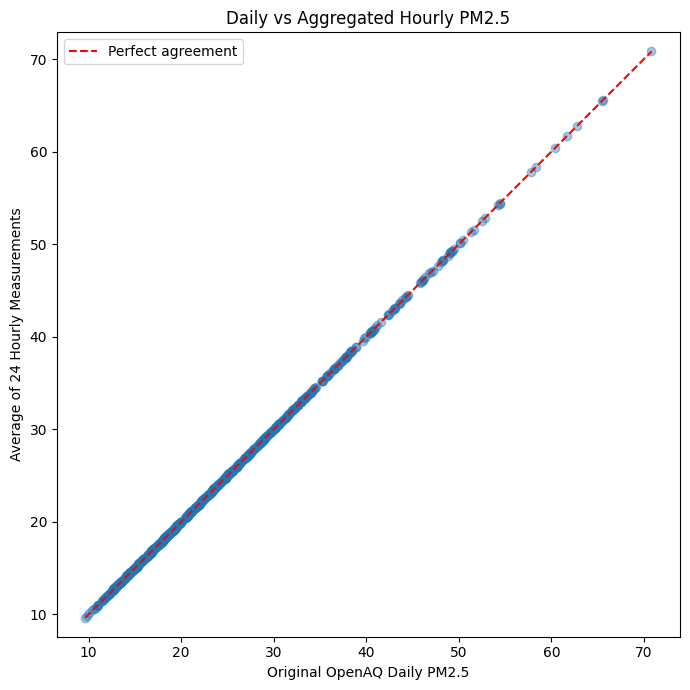

In [19]:
plt.figure(figsize=(7, 7))

plt.scatter(
    complete_days["pm25"],
    complete_days["hourly_mean"],
    alpha=0.4
)

lower = min(
    complete_days["pm25"].min(),
    complete_days["hourly_mean"].min()
)

upper = max(
    complete_days["pm25"].max(),
    complete_days["hourly_mean"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect agreement"
)

plt.xlabel("Original OpenAQ Daily PM2.5")
plt.ylabel("Average of 24 Hourly Measurements")
plt.title("Daily vs Aggregated Hourly PM2.5")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

In [20]:
merged_hourly = weather_df.merge(
    pm25_hourly,
    on="datetime",
    how="left",
    validate="one_to_one"
)

merged_hourly = (
    merged_hourly
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Merged shape:", merged_hourly.shape)

print("\nMissing values:")
print(merged_hourly.isna().sum())

display(merged_hourly.head(15))

Merged shape: (48264, 6)

Missing values:
datetime             0
temperature          0
humidity             0
wind_speed           0
precipitation        0
pm25             10824
dtype: int64


,datetime,temperature,humidity,wind_speed,precipitation,pm25
0,2021-04-30 00:00:00+07:00,25.3,92,2.4,0.4,NaN
1,2021-04-30 01:00:00+07:00,25.3,93,4.4,0.1,NaN
2,2021-04-30 02:00:00+07:00,25.1,94,4.3,0.1,19.0
3,2021-04-30 03:00:00+07:00,24.8,96,4.6,0.0,19.0
4,2021-04-30 04:00:00+07:00,24.6,97,4.9,0.0,20.0
5,2021-04-30 05:00:00+07:00,24.6,96,4.7,0.1,20.0
6,2021-04-30 06:00:00+07:00,24.6,96,2.7,0.1,21.0
7,2021-04-30 07:00:00+07:00,25.3,93,3.6,0.0,21.0
8,2021-04-30 08:00:00+07:00,26.3,87,6.4,0.0,21.0
9,2021-04-30 09:00:00+07:00,27.2,83,6.0,0.1,21.0


In [21]:
assert len(merged_hourly) == 48264

assert merged_hourly["datetime"].is_unique

assert merged_hourly["datetime"].is_monotonic_increasing

assert (
    merged_hourly["datetime"].diff().dropna()
    == pd.Timedelta(hours=1)
).all()

assert merged_hourly["pm25"].notna().sum() == 37440

output = (
    PROJECT_DIR
    / "data/processed/pm25_weather_hourly_merged.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

merged_hourly.to_csv(output, index=False)

print("Hourly merged dataset saved:", output)

Hourly merged dataset saved: /content/drive/MyDrive/PM25_Prediction/data/processed/pm25_weather_hourly_merged.csv


In [22]:
HORIZON = 24

window_results = []

for window in [6, 12, 24, 48, 72, 168]:

    total_window = window + HORIZON

    valid = (
        merged_hourly["pm25"]
        .notna()
        .rolling(total_window)
        .sum()
        .eq(total_window)
    )

    target_end = merged_hourly["datetime"]

    target_start = (
        target_end
        - pd.Timedelta(hours=HORIZON - 1)
    )

    train = (
        valid
        & (target_end < "2025-01-01")
    )

    val = (
        valid
        & (target_start >= "2025-01-01")
        & (target_end < "2026-01-01")
    )

    test = (
        valid
        & (target_start >= "2026-01-01")
    )

    midnight = target_start.dt.hour.eq(0)

    window_results.append({
        "input_hours": window,
        "train_samples": train.sum(),
        "val_samples": val.sum(),
        "test_samples": test.sum(),
        "val_midnight_samples": (val & midnight).sum(),
        "test_midnight_samples": (test & midnight).sum()
    })

window_results = pd.DataFrame(window_results)

display(window_results)

,input_hours,train_samples,val_samples,test_samples,val_midnight_samples,test_midnight_samples
0,6,12020,1259,2239,36,72
1,12,10922,980,1837,32,63
2,24,9068,544,1232,22,51
3,48,6692,132,628,5,26
4,72,5208,49,361,2,14
5,168,1987,0,2,0,0


# EDA

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
import pandas as pd

pm25_path = (
    PROJECT_DIR / "data/raw/pm25_data_2021-2026.csv"
)

weather_path = (
    PROJECT_DIR / "data/raw/weather_data_2021-2026.csv"
)

pm25 = pd.read_csv(pm25_path)
weather = pd.read_csv(weather_path)

print("PM2.5:", pm25.shape)
print("Weather:", weather.shape)

PM2.5: (1773, 2)
Weather: (2011, 5)


In [ ]:
pm25["date"] = pd.to_datetime(pm25["date"])

weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temperature",
    "relative_humidity_2m_mean": "humidity",
    "wind_speed_10m_mean": "wind_speed",
    "precipitation_sum": "precipitation"
})

weather["date"] = pd.to_datetime(weather["date"])

Merge data

In [ ]:
merged = weather.merge(
    pm25,
    on="date",
    how="left",
    validate="one_to_one"
)

merged = merged.sort_values("date").reset_index(drop=True)

print("Merged shape:", merged.shape)
print(merged.head(10))

Merged shape: (2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
print("Date range:")
print(merged["date"].min(), merged["date"].max())

print("\nMissing values:")
print(merged.isna().sum())

print("\nDuplicate dates:")
print(merged["date"].duplicated().sum())

print("\nSummary statistics:")
print(merged.describe())

Date range:
2021-04-30 00:00:00 2026-10-31 00:00:00

Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64

Duplicate dates:
0

Summary statistics:
                      date  temperature     humidity   wind_speed  \
count                 2011  2011.000000  2011.000000  2011.000000   
mean   2024-01-30 00:00:00    28.262108    74.235704     8.021382   
min    2021-04-30 00:00:00    21.800000    39.000000     1.800000   
25%    2022-09-14 12:00:00    27.300000    68.000000     6.100000   
50%    2024-01-30 00:00:00    28.200000    77.000000     7.700000   
75%    2025-06-15 12:00:00    29.300000    83.000000     9.700000   
max    2026-10-31 00:00:00    33.200000    95.000000    17.200000   
std                    NaN     1.692652    10.790042     2.608408   

       precipitation         pm25  
count    2011.000000  1773.000000  
mean        5.052312    24.463463  
min         0.000000 

In [ ]:
output = (
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

merged.to_csv(output, index=False)

print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/data/processed/pm25_weather_merged.csv


In [ ]:
print("Merged shape:", merged.shape)
print("Missing values:")
print(merged.isna().sum())
print("First 10 rows:")
print(merged.head(10))

Merged shape: (2011, 6)
Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64
First 10 rows:
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print(df.shape)
print(df.head())

(2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0


Choose training data to be before 2025

In [ ]:
eda_df = df[
    df["date"] < "2025-01-01"
].copy()

print("Training period:")
print(eda_df["date"].min())
print(eda_df["date"].max())

print("Calendar days:", len(eda_df))
print("Observed PM2.5:", eda_df["pm25"].count())

Training period:
2021-04-30 00:00:00
2024-12-31 00:00:00
Calendar days: 1342
Observed PM2.5: 1237


In [ ]:
print(eda_df.describe().round(2))

                      date  temperature  humidity  wind_speed  precipitation  \
count                 1342      1342.00   1342.00     1342.00        1342.00   
mean   2023-03-01 12:00:00        28.08     75.40        8.78           5.08   
min    2021-04-30 00:00:00        21.80     45.00        2.30           0.00   
25%    2022-03-31 06:00:00        27.12     70.00        6.90           0.00   
50%    2023-03-01 12:00:00        28.00     78.00        8.60           1.60   
75%    2024-01-30 18:00:00        29.10     83.00       10.40           7.40   
max    2024-12-31 00:00:00        33.20     92.00       17.20          56.80   
std                    NaN         1.70      9.74        2.57           7.55   

          pm25  
count  1237.00  
mean     24.28  
min       8.91  
25%      16.70  
50%      21.00  
75%      29.30  
max      70.80  
std      10.30  


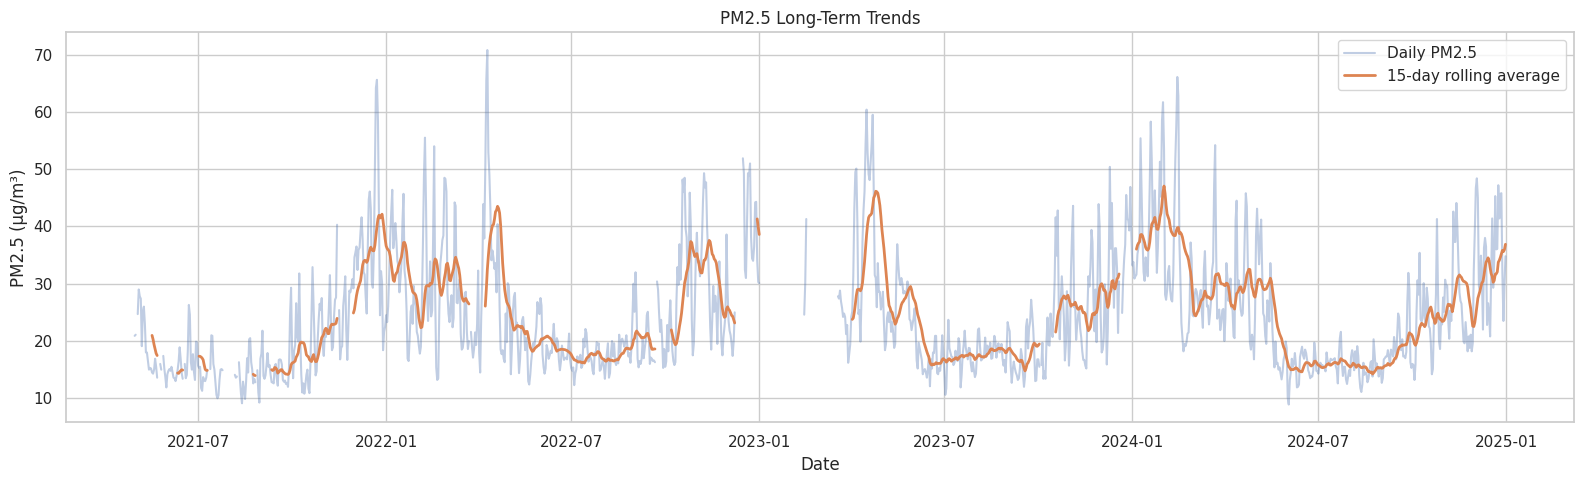

In [ ]:
eda_df["pm25_rolling_15"] = (
    eda_df["pm25"]
    .rolling(window=15, min_periods=15)
    .mean()
)

plt.figure(figsize=(16, 5))

plt.plot(
    eda_df["date"],
    eda_df["pm25"],
    alpha=0.35,
    label="Daily PM2.5"
)

plt.plot(
    eda_df["date"],
    eda_df["pm25_rolling_15"],
    linewidth=2,
    label="15-day rolling average"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 Long-Term Trends")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pm25_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PM2.5 distribution

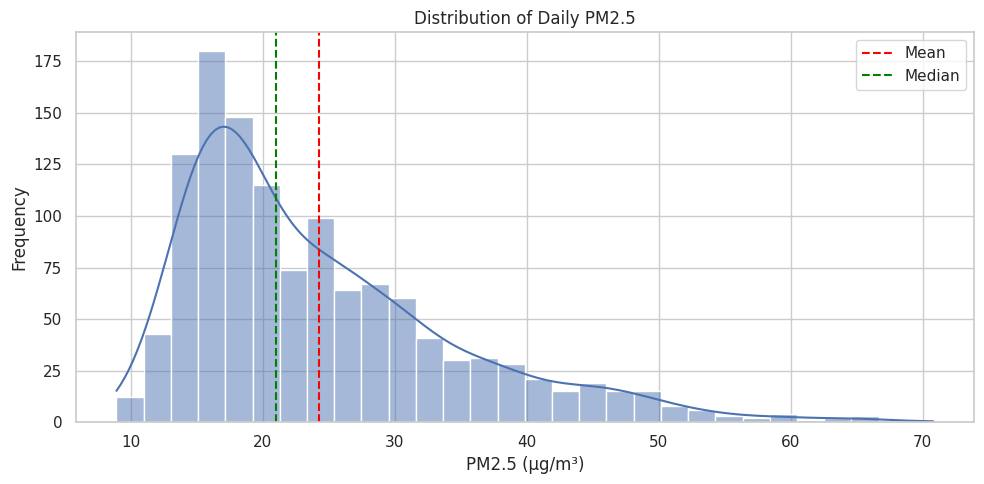

Skewness: 1.2852815569856226


In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df["pm25"].dropna(),
    bins=30,
    kde=True
)

plt.axvline(
    eda_df["pm25"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    eda_df["pm25"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

print("Skewness:", eda_df["pm25"].skew())

Monthly seasonal analysis

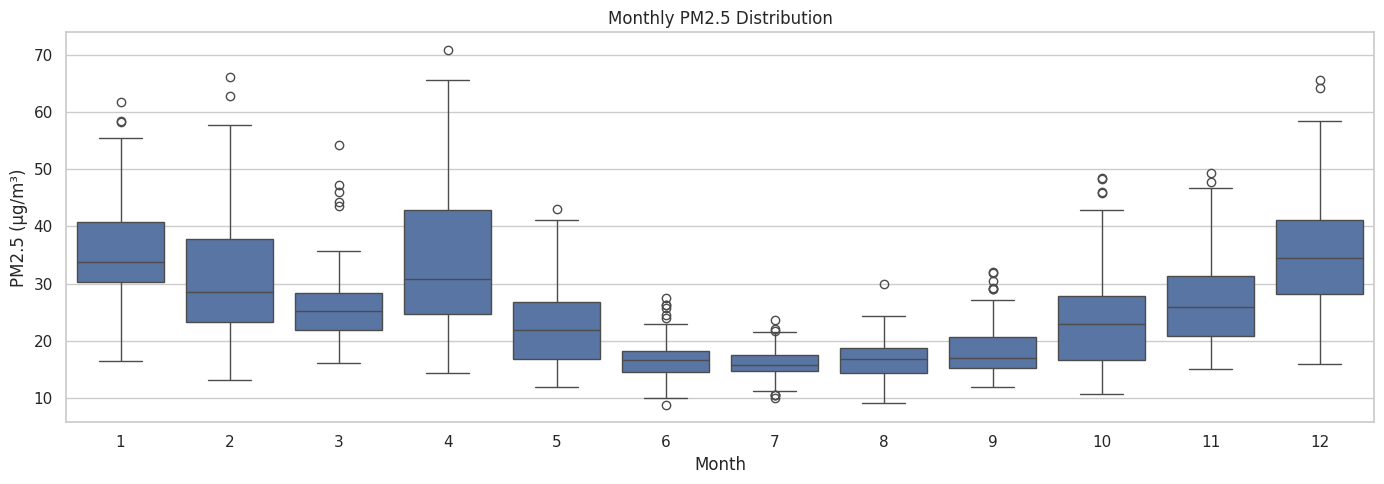

In [ ]:
eda_df["month"] = eda_df["date"].dt.month

plt.figure(figsize=(14, 5))

sns.boxplot(
    data=eda_df,
    x="month",
    y="pm25"
)

plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Monthly PM2.5 Distribution")
plt.tight_layout()
plt.show()

In [ ]:
monthly_stats = (
    eda_df.groupby("month")["pm25"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(monthly_stats)

       count   mean  median    std    min   max
month                                          
1         63  35.62   33.80   9.86  16.50  61.7
2         60  32.13   28.60  12.56  13.20  66.1
3         74  26.38   25.30   7.07  16.20  54.2
4         91  33.45   30.80  12.40  14.50  70.8
5        120  22.50   21.95   6.70  11.90  43.1
6        119  16.81   16.70   3.23   8.91  27.5
7        116  16.11   15.85   2.63  10.00  23.7
8        118  16.59   16.80   3.18   9.13  30.0
9        119  18.24   17.00   4.65  12.00  32.0
10       123  23.73   22.90   8.49  10.80  48.5
11       119  27.41   26.00   7.98  15.20  49.3
12       115  34.69   34.50  10.00  15.90  65.6


Weather correlation analysis

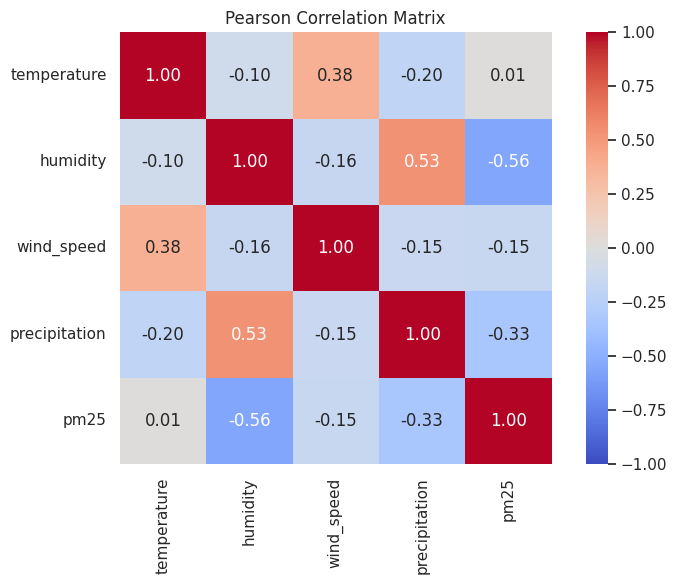

humidity        -0.561438
precipitation   -0.328966
wind_speed      -0.150912
temperature      0.009666
pm25             1.000000
Name: pm25, dtype: float64


In [ ]:
features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation",
    "pm25"
]

correlation = eda_df[features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

print(correlation["pm25"].sort_values())

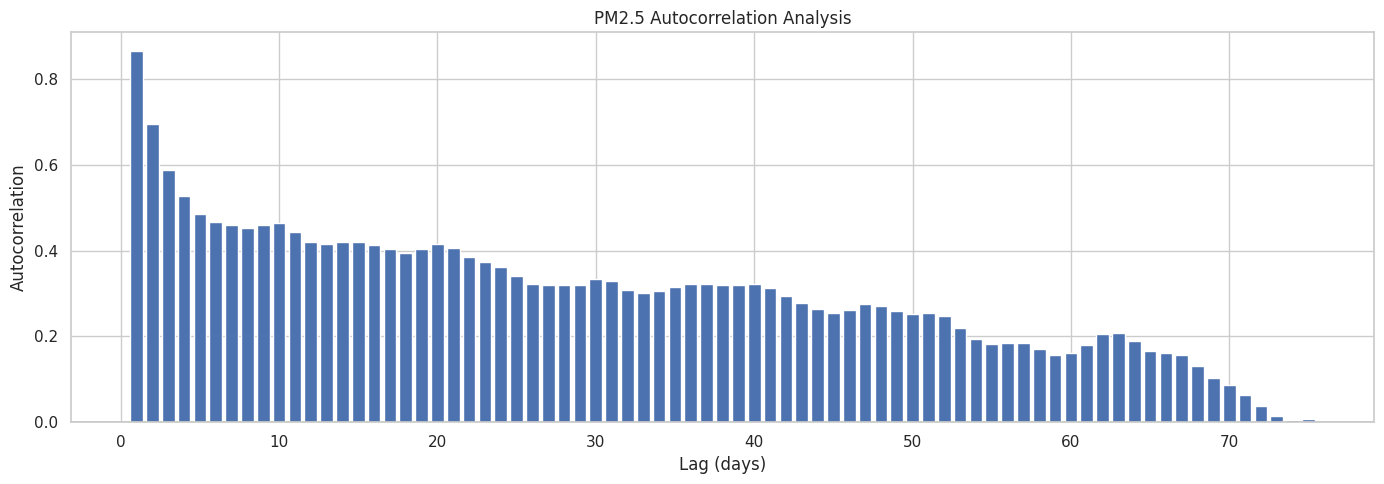

In [ ]:
max_lag = 75

acf_results = []

for lag in range(1, max_lag + 1):

    correlation = eda_df["pm25"].corr(
        eda_df["pm25"].shift(lag)
    )

    acf_results.append({
        "lag": lag,
        "correlation": correlation
    })

acf_df = pd.DataFrame(acf_results)

plt.figure(figsize=(14, 5))

plt.bar(
    acf_df["lag"],
    acf_df["correlation"]
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.title("PM2.5 Autocorrelation Analysis")
plt.tight_layout()
plt.show()

In [ ]:
print(
    acf_df[
        acf_df["lag"].isin(
            [1, 2, 3, 5, 7, 14, 21, 30, 60, 75]
        )
    ].round(3)
)

    lag  correlation
0     1        0.865
1     2        0.695
2     3        0.589
4     5        0.484
6     7        0.459
13   14        0.421
20   21        0.406
29   30        0.335
59   60        0.161
74   75        0.007


Weather yesterday and pm2.5 today correlation

In [ ]:
weather_features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

tomorrow_pm25 = eda_df["pm25"].shift(-1)

for feature in weather_features:

    r = eda_df[feature].corr(tomorrow_pm25)

    print(f"{feature:15}: {r:.3f}")

temperature    : -0.051
humidity       : -0.588
wind_speed     : -0.173
precipitation  : -0.338


# Feature engineering

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

df = df.sort_values("date").reset_index(drop=True)

Choosing what window would be suitable

In [ ]:
window_results = []

for window in [1, 3, 7, 14, 30]:

    # Check whether every historical input
    # and the target are available
    valid = (
        df["pm25"]
        .notna()
        .rolling(window=window + 1)
        .sum()
        .eq(window + 1)
    )

    train = (
        valid &
        (df["date"] < "2025-01-01")
    )

    val = (
        valid &
        (df["date"] >= "2025-01-01") &
        (df["date"] < "2026-01-01")
    )

    test = (
        valid &
        (df["date"] >= "2026-01-01")
    )

    window_results.append({
        "window_size": window,
        "train_samples": train.sum(),
        "val_samples": val.sum(),
        "test_samples": test.sum(),
        "total_samples": valid.sum()
    })

window_results = pd.DataFrame(window_results)

print(window_results)

   window_size  train_samples  val_samples  test_samples  total_samples
0            1           1219          254           276           1749
1            3           1187          244           274           1705
2            7           1135          224           270           1629
3           14           1045          189           263           1497
4           30            906          141           244           1291


In [ ]:
FEATURES = [
    "pm25",
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

TARGET = "pm25"

WINDOW_SIZE = 7

In [ ]:
def create_sequences(df, features, target, window_size):

    X = []
    y = []
    dates = []

    for i in range(window_size, len(df)):

        # Historical input
        input_window = df.iloc[i-window_size:i][features]

        # Prediction target
        target_value = df.iloc[i][target]

        # Skip missing historical inputs
        if input_window.isna().any().any():
            continue

        # Skip missing prediction target
        if pd.isna(target_value):
            continue

        X.append(input_window.to_numpy())
        y.append(target_value)
        dates.append(df.iloc[i]["date"])

    return (
        np.array(X),
        np.array(y),
        pd.DatetimeIndex(dates)
    )

In [ ]:
X, y, target_dates = create_sequences(
    df,
    FEATURES,
    TARGET,
    WINDOW_SIZE
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target dates shape:", target_dates.shape)

X shape: (1629, 7, 5)
y shape: (1629,)
Target dates shape: (1629,)


In [ ]:
print("First input sample:")

print(
    pd.DataFrame(
        X[0],
        columns=FEATURES
    )
)

print("\nTarget PM2.5:", y[0])
print("Target date:", target_dates[0])

First input sample:
   pm25  temperature  humidity  wind_speed  precipitation
0  24.7         29.0      81.0         3.3            1.6
1  29.0         29.5      81.0         4.7           13.9
2  27.8         29.8      79.0         4.6            0.0
3  27.4         27.1      87.0         7.1           10.8
4  19.1         27.5      84.0         7.4            2.8
5  25.2         28.1      85.0         4.5            0.8
6  26.0         28.5      82.0         5.2            1.2

Target PM2.5: 23.0
Target date: 2021-05-10 00:00:00


In [ ]:
train_mask = target_dates < "2025-01-01"

val_mask = (
    (target_dates >= "2025-01-01") &
    (target_dates < "2026-01-01")
)

test_mask = target_dates >= "2026-01-01"

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

dates_train = target_dates[train_mask]
dates_val = target_dates[val_mask]
dates_test = target_dates[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1135, 7, 5) (1135,)
Validation: (224, 7, 5) (224,)
Testing: (270, 7, 5) (270,)


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

In [ ]:
output = (
    PROJECT_DIR
    / "data/processed/dataset_window7.npz"
)

np.savez_compressed(
    output,

    X_train=X_train,
    y_train=y_train,

    X_val=X_val,
    y_val=y_val,

    X_test=X_test,
    y_test=y_test,

    dates_train=dates_train.to_numpy(),
    dates_val=dates_val.to_numpy(),
    dates_test=dates_test.to_numpy(),

    features=np.array(FEATURES),
    window_size=WINDOW_SIZE
)

print("Dataset saved:", output)

Dataset saved: /content/drive/MyDrive/PM25_Prediction/data/processed/dataset_window7.npz


In [ ]:
with np.load(output) as dataset:

    print("Stored arrays:", dataset.files)

    print("Training:", dataset["X_train"].shape)
    print("Validation:", dataset["X_val"].shape)
    print("Testing:", dataset["X_test"].shape)

    assert np.array_equal(
        dataset["X_train"], X_train
    )

    assert np.array_equal(
        dataset["y_train"], y_train
    )

Stored arrays: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'dates_train', 'dates_val', 'dates_test', 'features', 'window_size']
Training: (1135, 7, 5)
Validation: (224, 7, 5)
Testing: (270, 7, 5)


# Persistence baseline

Base line:
predicting tomorrow's concentration using today's concentration

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

In [ ]:
dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()

print("Features:", FEATURES)

Features: ['pm25', 'temperature', 'humidity', 'wind_speed', 'precipitation']


In [ ]:
pm25_index = FEATURES.index("pm25")

y_train_pred = X_train[:, -1, pm25_index]
y_val_pred = X_val[:, -1, pm25_index]

print("First 5 predictions:", y_val_pred[:5])
print("First 5 actual values:", y_val[:5])

First 5 predictions: [34.8 35.1 39.4 43.  35.7]
First 5 actual values: [35.1 39.4 43.  35.7 41. ]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [ ]:
train_results = evaluate_model(
    y_train, y_train_pred
)

val_results = evaluate_model(
    y_val, y_val_pred
)

results = pd.DataFrame(
    [train_results, val_results],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    3.7920  5.4096  0.7263
Validation  4.3737  6.2417  0.8117


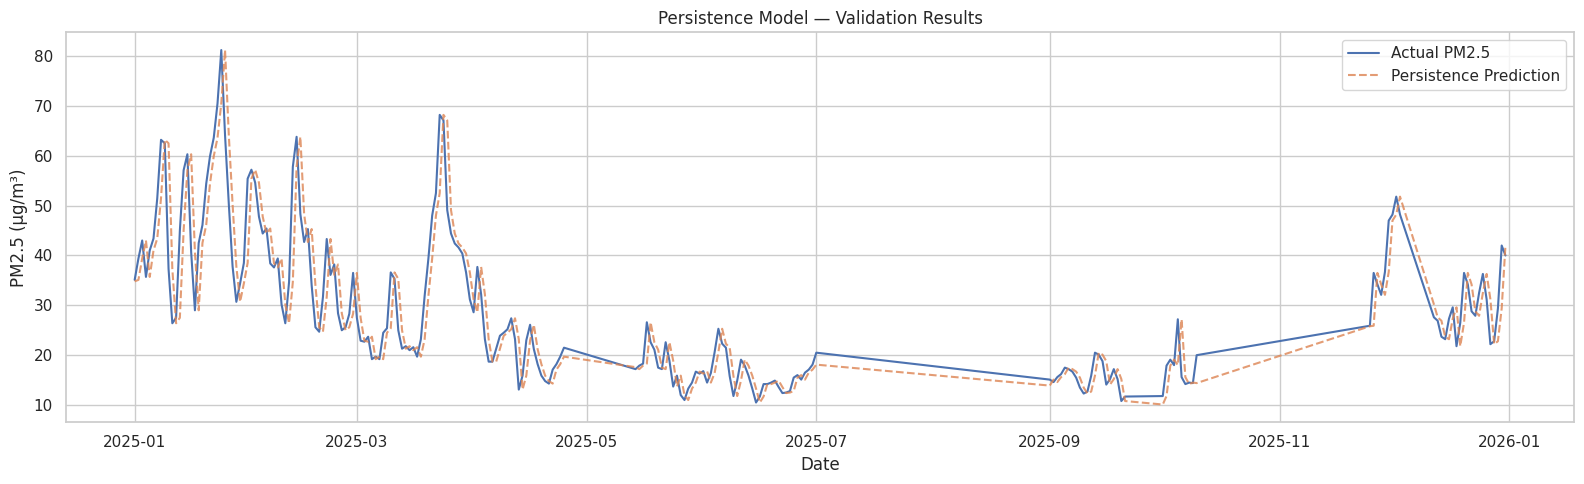

In [ ]:
plt.figure(figsize=(16, 5))

plt.plot(
    dates_val,
    y_val,
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    dates_val,
    y_val_pred,
    label="Persistence Prediction",
    linestyle="--",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence Model — Validation Results")
plt.legend()
plt.tight_layout()
plt.show()

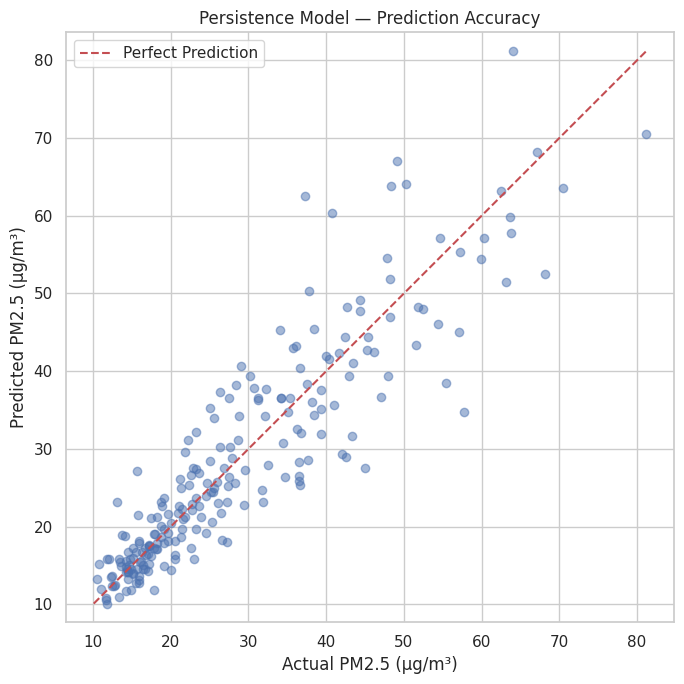

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    y_val_pred,
    alpha=0.5
)

lower = min(y_val.min(), y_val_pred.min())
upper = max(y_val.max(), y_val_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("Persistence Model — Prediction Accuracy")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (1135, 7, 5)
Validation: (224, 7, 5)


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)

Training: (1135, 35)
Validation: (224, 35)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
import time

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_model.fit(X_train_flat, y_train)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.3f} seconds")

Training time: 3.463 seconds


In [ ]:
y_train_pred = rf_model.predict(X_train_flat)
y_val_pred = rf_model.predict(X_val_flat)

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame(
    [
        evaluate_model(y_train, y_train_pred),
        evaluate_model(y_val, y_val_pred)
    ],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    1.2936  1.8149  0.9692
Validation  4.5794  6.6754  0.7846


In [ ]:
pm25_index = FEATURES.index("pm25")

persistence_pred = X_val[:, -1, pm25_index]

comparison = pd.DataFrame({
    "Persistence": evaluate_model(
        y_val, persistence_pred
    ),
    "Random Forest": evaluate_model(
        y_val, y_val_pred
    )
}).T

print(comparison.round(4))

                  MAE    RMSE      R2
Persistence    4.3737  6.2417  0.8117
Random Forest  4.5794  6.6754  0.7846


In [ ]:
for metric in ["MAE", "RMSE"]:

    baseline = comparison.loc["Persistence", metric]
    rf = comparison.loc["Random Forest", metric]

    improvement = (baseline - rf) / baseline * 100

    print(f"{metric} improvement: {improvement:.2f}%")

MAE improvement: -4.70%
RMSE improvement: -6.95%


In [ ]:
feature_names = [
    f"{feature}_lag{lag}"
    for lag in range(WINDOW_SIZE, 0, -1)
    for feature in FEATURES
]

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance.head(15))

               feature  importance
30           pm25_lag1    0.762973
28     wind_speed_lag2    0.018114
34  precipitation_lag1    0.016473
33     wind_speed_lag1    0.013375
25           pm25_lag2    0.012961
32       humidity_lag1    0.012952
23     wind_speed_lag3    0.011652
31    temperature_lag1    0.009406
13     wind_speed_lag5    0.008320
26    temperature_lag2    0.008279
0            pm25_lag7    0.008214
8      wind_speed_lag6    0.007100
10           pm25_lag5    0.006937
29  precipitation_lag2    0.006928
27       humidity_lag2    0.006791


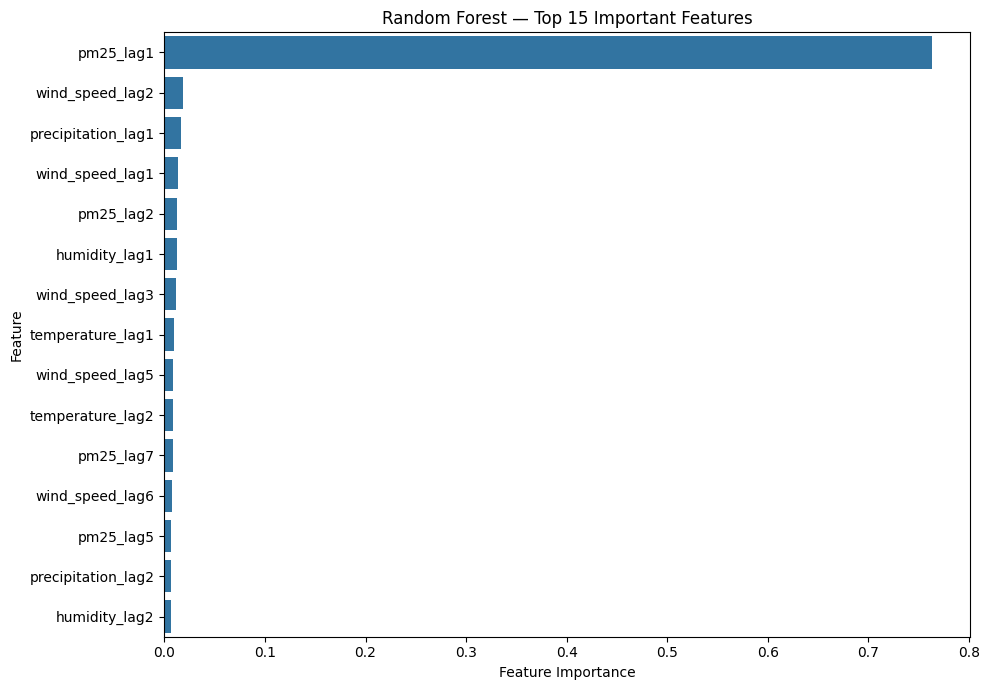

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="importance",
    y="feature"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 15 Important Features")
plt.tight_layout()
plt.show()

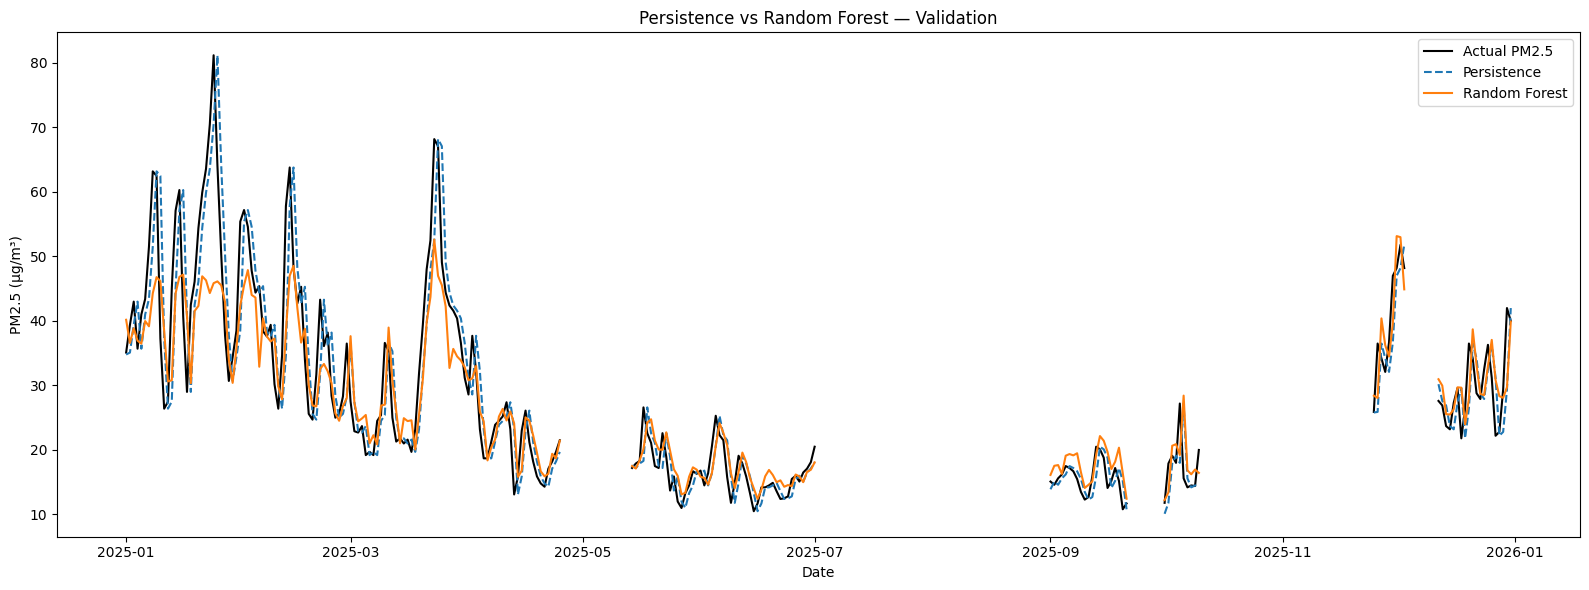

In [ ]:
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": persistence_pred,
    "Random Forest": y_val_pred
}, index=pd.to_datetime(dates_val))

full_dates = pd.date_range(
    "2025-01-01",
    "2025-12-31",
    freq="D"
)

plot_df = plot_df.reindex(full_dates)

plt.figure(figsize=(16, 6))

plt.plot(
    plot_df.index,
    plot_df["Actual"],
    color="black",
    label="Actual PM2.5"
)

plt.plot(
    plot_df.index,
    plot_df["Persistence"],
    linestyle="--",
    label="Persistence"
)

plt.plot(
    plot_df.index,
    plot_df["Random Forest"],
    label="Random Forest"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence vs Random Forest — Validation")
plt.legend()
plt.tight_layout()
plt.show()

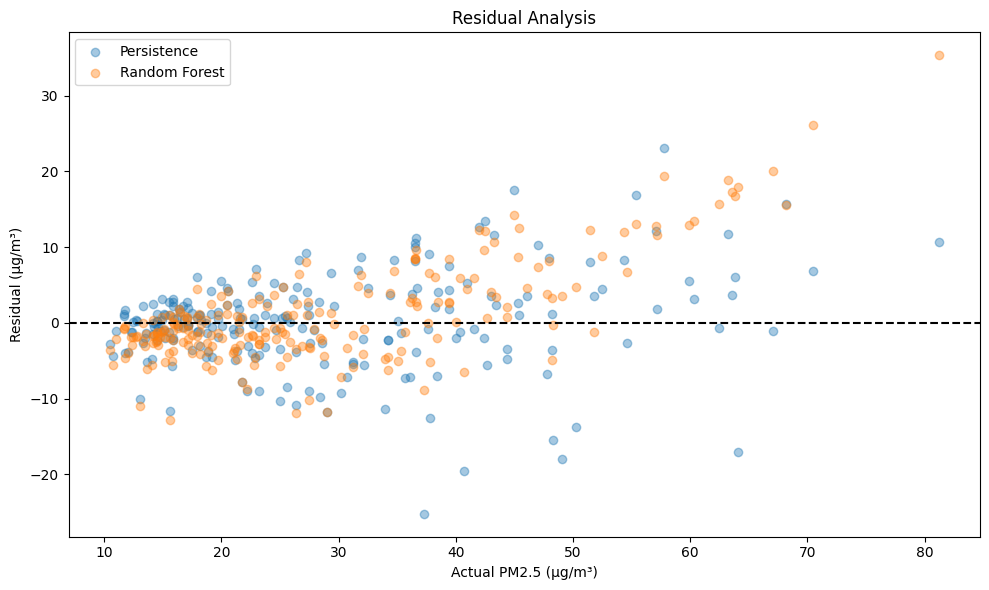

In [ ]:
persistence_residuals = y_val - persistence_pred
rf_residuals = y_val - y_val_pred

plt.figure(figsize=(10, 6))

plt.scatter(
    y_val,
    persistence_residuals,
    alpha=0.4,
    label="Persistence"
)

plt.scatter(
    y_val,
    rf_residuals,
    alpha=0.4,
    label="Random Forest"
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.title("Residual Analysis")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
grouped_importance = importance.copy()

grouped_importance["variable"] = (
    grouped_importance["feature"]
    .str.replace(r"_lag\d+$", "", regex=True)
)

grouped_importance = (
    grouped_importance
    .groupby("variable")["importance"]
    .sum()
    .sort_values(ascending=False)
)

print(grouped_importance)

variable
pm25             0.808451
wind_speed       0.068585
precipitation    0.045618
humidity         0.039340
temperature      0.038005
Name: importance, dtype: float64


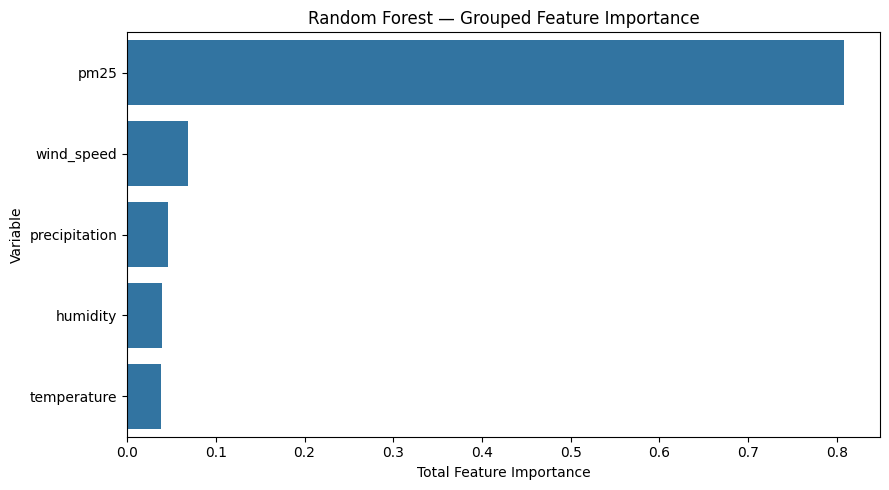

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=grouped_importance.values,
    y=grouped_importance.index
)

plt.xlabel("Total Feature Importance")
plt.ylabel("Variable")
plt.title("Random Forest — Grouped Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
print("Training maximum:", y_train.max())
print("Validation maximum:", y_val.max())
print("Random Forest maximum:", y_val_pred.max())
print("Persistence maximum:", persistence_pred.max())

Training maximum: 70.8
Validation maximum: 81.2
Random Forest maximum: 53.159
Persistence maximum: 81.2


In [ ]:
error_analysis = pd.DataFrame({
    "actual": y_val,
    "persistence": persistence_pred,
    "random_forest": y_val_pred
})

error_analysis["pollution_level"] = pd.cut(
    error_analysis["actual"],
    bins=[0, 20, 35, 50, np.inf],
    labels=["0-20", "20-35", "35-50", "50+"],
    include_lowest=True
)

for model in ["persistence", "random_forest"]:

    error_analysis[f"{model}_residual"] = (
        error_analysis["actual"]
        - error_analysis[model]
    )

    error_analysis[f"{model}_abs_error"] = (
        error_analysis[f"{model}_residual"].abs()
    )

summary = (
    error_analysis
    .groupby("pollution_level", observed=True)
    .agg(
        samples=("actual", "size"),
        persistence_MAE=("persistence_abs_error", "mean"),
        rf_MAE=("random_forest_abs_error", "mean"),
        persistence_bias=("persistence_residual", "mean"),
        rf_bias=("random_forest_residual", "mean")
    )
)

print(summary.round(3))

                 samples  persistence_MAE  rf_MAE  persistence_bias  rf_bias
pollution_level                                                             
0-20                  83            2.027   2.407            -0.460   -1.865
20-35                 74            4.253   3.535            -0.836   -1.267
35-50                 46            6.950   5.463             0.502    3.822
50+                   21            8.433  14.911             5.071   14.797


In [ ]:
depth_results = []

for depth in [3, 5, 7, 10, 15, None]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(y_train, train_pred)
    val_metrics = evaluate_model(y_val, val_pred)

    depth_results.append({
        "max_depth": str(depth),
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

depth_results = pd.DataFrame(depth_results)

print(depth_results.round(4))

  max_depth  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  training_time
0         3     3.4944      4.7815   4.6929    7.0005  0.7631         0.4728
1         5     2.8456      3.8189   4.5549    6.7256  0.7814         0.7666
2         7     2.2286      2.9186   4.5386    6.6097  0.7888         1.0781
3        10     1.6110      2.1181   4.5126    6.5569  0.7922         1.5170
4        15     1.3208      1.8317   4.5157    6.5262  0.7941         1.9542
5      None     1.2936      1.8149   4.5794    6.6754  0.7846         2.0194


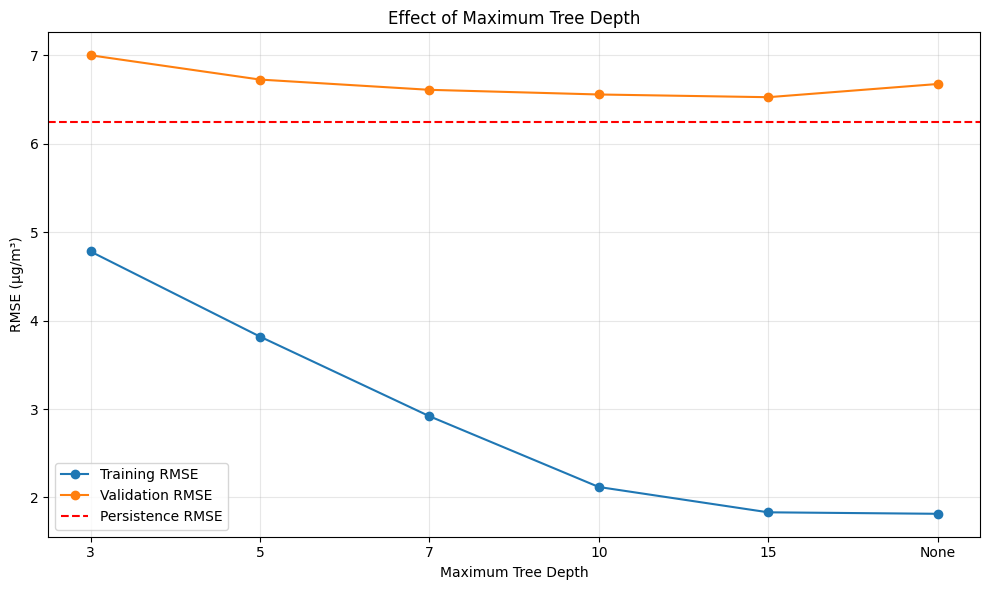

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    depth_results["max_depth"],
    depth_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    depth_results["max_depth"],
    depth_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Maximum Tree Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
leaf_results = []

for leaf in [1, 2, 4, 8, 16, 32]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    leaf_results.append({
        "min_samples_leaf": leaf,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

leaf_results = pd.DataFrame(leaf_results)

print(leaf_results.round(4))

   min_samples_leaf  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0                 1     1.3208      1.8317   4.5157    6.5262  0.7941   
1                 2     1.4369      2.0644   4.4914    6.5542  0.7924   
2                 4     1.8180      2.6504   4.5677    6.7460  0.7800   
3                 8     2.3966      3.4153   4.5541    6.7660  0.7787   
4                16     2.9128      4.1384   4.5541    6.6840  0.7841   
5                32     3.3087      4.6867   4.5734    6.6230  0.7880   

   training_time  
0         2.4400  
1         2.7864  
2         1.5790  
3         1.0037  
4         0.7777  
5         0.6082  


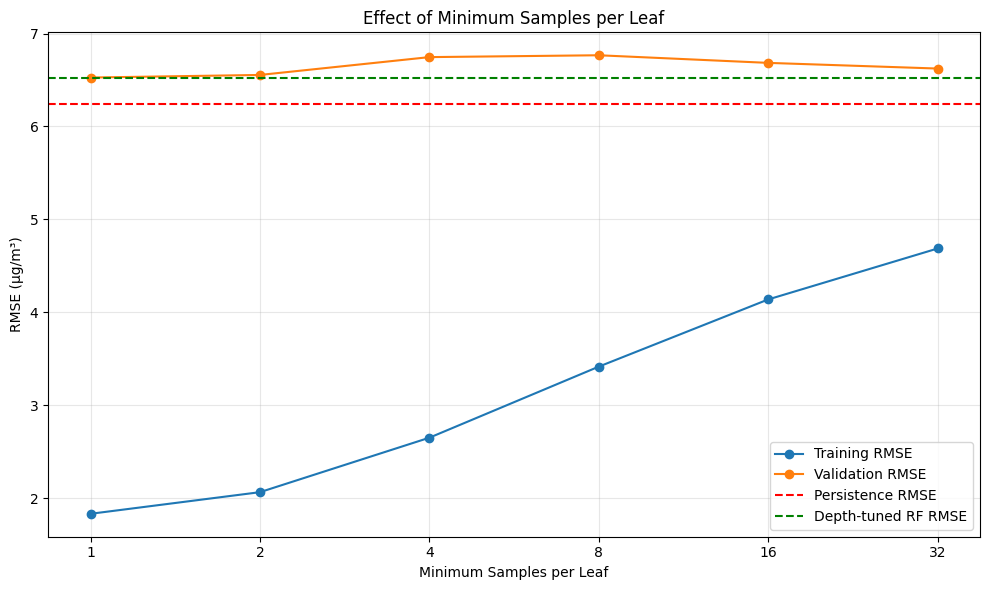

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    leaf_results["min_samples_leaf"],
    leaf_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    leaf_results["min_samples_leaf"],
    leaf_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.axhline(
    6.5262,
    color="green",
    linestyle="--",
    label="Depth-tuned RF RMSE"
)

plt.xscale("log", base=2)

plt.xticks(
    [1, 2, 4, 8, 16, 32],
    [1, 2, 4, 8, 16, 32]
)

plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Minimum Samples per Leaf")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
estimator_results = []

for n in [10, 25, 50, 100, 200, 300, 500, 1000]:

    model = RandomForestRegressor(
        n_estimators=n,
        max_depth=15,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    estimator_results.append({
        "n_estimators": n,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

estimator_results = pd.DataFrame(estimator_results)

print(estimator_results.round(4))

   n_estimators  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0            10     1.4841      2.2130   4.6608    6.7274  0.7812   
1            25     1.3650      1.9504   4.6478    6.6541  0.7860   
2            50     1.3297      1.8654   4.5576    6.5990  0.7895   
3           100     1.3208      1.8317   4.5157    6.5262  0.7941   
4           200     1.3035      1.7993   4.5311    6.5837  0.7905   
5           300     1.3041      1.7974   4.5425    6.6142  0.7885   
6           500     1.3041      1.7967   4.5784    6.6886  0.7838   
7          1000     1.2982      1.7914   4.5599    6.6634  0.7854   

   training_time  
0         0.2027  
1         0.5190  
2         0.9667  
3         1.9118  
4         4.7377  
5         6.6927  
6        11.5508  
7        21.1143  


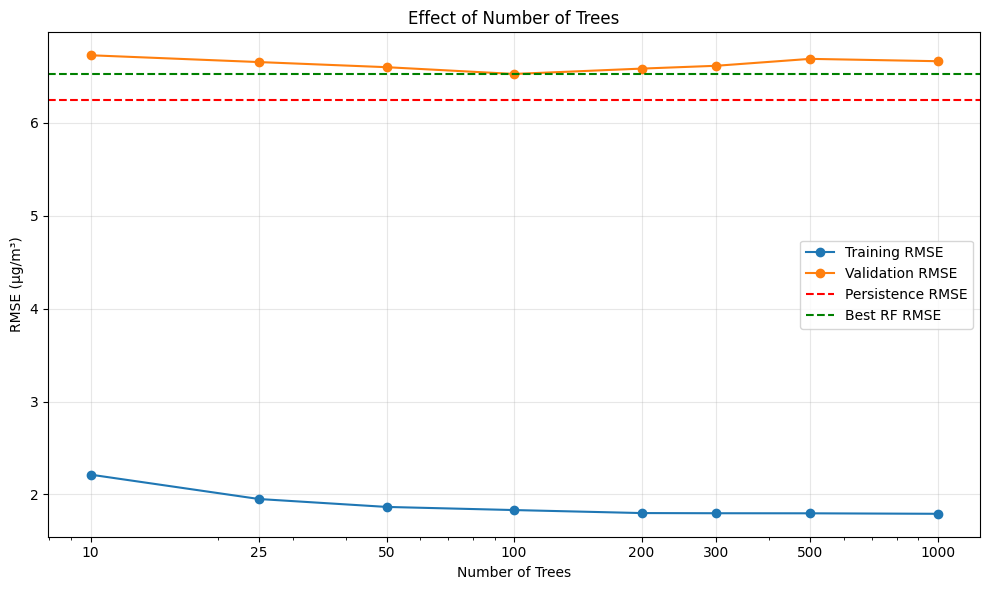

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    estimator_results["n_estimators"],
    estimator_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    estimator_results["n_estimators"],
    estimator_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.axhline(
    6.5262,
    color="green",
    linestyle="--",
    label="Best RF RMSE"
)

plt.xscale("log")

plt.xticks(
    estimator_results["n_estimators"],
    estimator_results["n_estimators"]
)

plt.xlabel("Number of Trees")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Number of Trees")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
max_features_results = []

for max_f in ["sqrt", 0.3, 0.5, 0.7, 1.0]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=1,
        max_features=max_f,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    max_features_results.append({
        "max_features": str(max_f),
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

max_features_results = pd.DataFrame(
    max_features_results
)

print(max_features_results.round(4))

  max_features  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0         sqrt     1.4970      2.0307   5.2256    7.2416  0.7465   
1          0.3     1.3900      1.9028   4.6341    6.6002  0.7894   
2          0.5     1.3668      1.8924   4.4867    6.4152  0.8011   
3          0.7     1.3258      1.8382   4.4756    6.4100  0.8014   
4          1.0     1.3208      1.8317   4.5157    6.5262  0.7941   

   training_time  
0         0.4114  
1         0.7187  
2         1.7839  
3         2.5285  
4         1.9718  


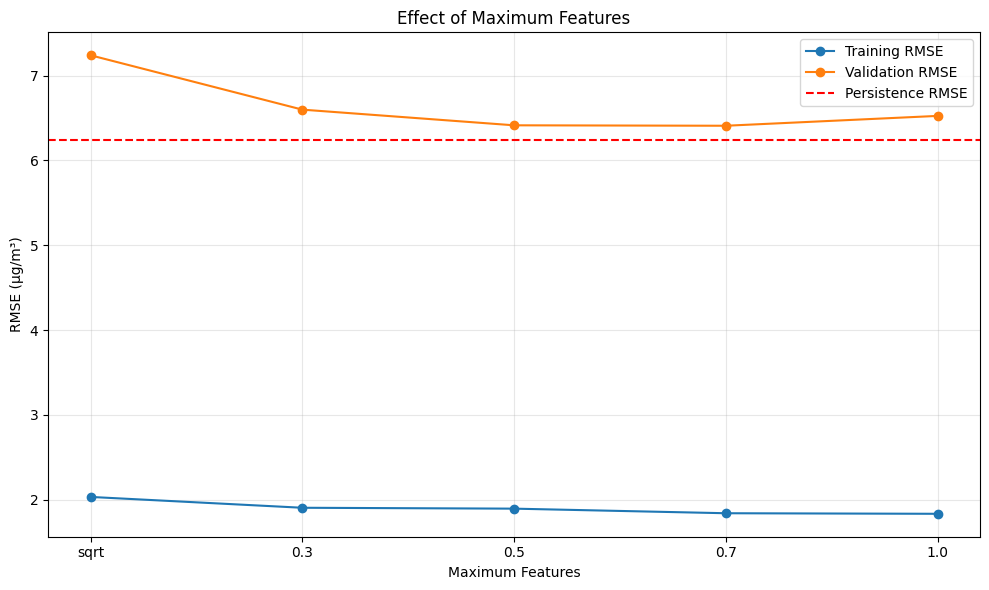

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    max_features_results["max_features"],
    max_features_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    max_features_results["max_features"],
    max_features_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.xlabel("Maximum Features")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Maximum Features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_flat, y_train)

tuned_train_pred = rf_tuned.predict(X_train_flat)
tuned_val_pred = rf_tuned.predict(X_val_flat)

output = PROJECT_DIR / "models/random_forest_tuned.joblib"

output.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(rf_tuned, output)

print("Model saved:", output)

print(evaluate_model(y_val, tuned_val_pred))

Model saved: /content/drive/MyDrive/PM25_Prediction/models/random_forest_tuned.joblib
{'MAE': 4.475593825936897, 'RMSE': np.float64(6.4099760574585245), 'R2': 0.8014028551744836}


# Residual Random forest

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/PM25_Prediction


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (1135, 7, 5)
Validation: (224, 7, 5)


In [ ]:
pm25_index = FEATURES.index("pm25")

# Today's PM2.5 for every sample
today_train = X_train[:, -1, pm25_index]
today_val = X_val[:, -1, pm25_index]

# Tomorrow's PM2.5 minus today's PM2.5
y_train_delta = y_train - today_train
y_val_delta = y_val - today_val

print("Original targets:", y_train[:5])
print("Today's PM2.5:", today_train[:5])
print("Residual targets:", y_train_delta[:5])

Original targets: [23.  18.  18.  16.5 15. ]
Today's PM2.5: [26.  23.  18.  18.  16.5]
Residual targets: [-3.  -5.   0.  -1.5 -1.5]


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)

Training: (1135, 35)
Validation: (224, 35)


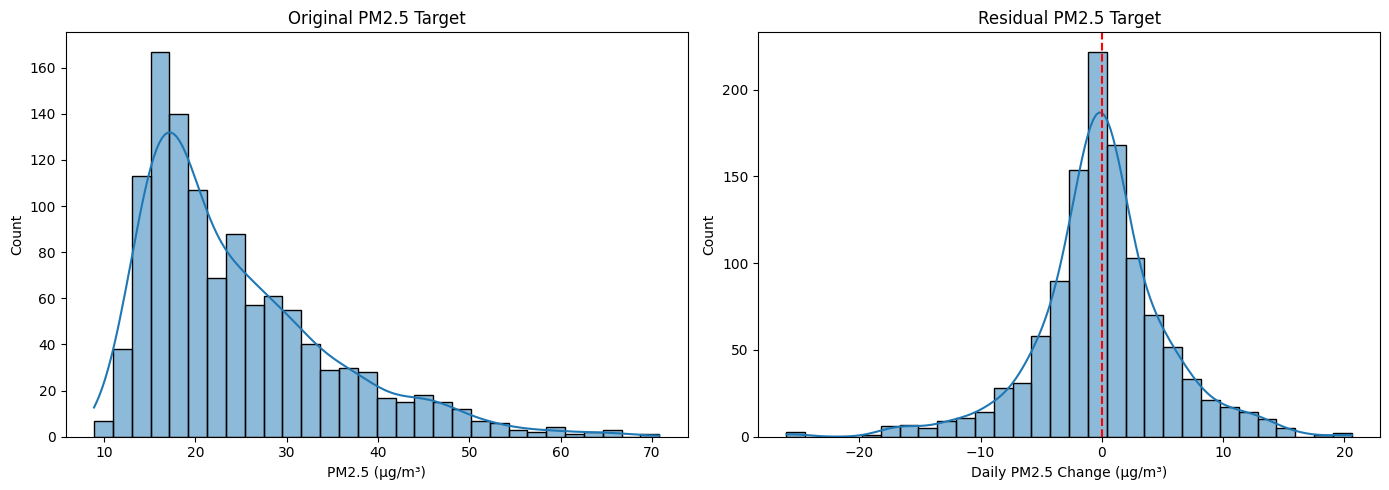

In [ ]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original PM2.5 Target")
axes[0].set_xlabel("PM2.5 (µg/m³)")

sns.histplot(
    y_train_delta,
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residual PM2.5 Target")
axes[1].set_xlabel("Daily PM2.5 Change (µg/m³)")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import time

rf_residual = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_residual.fit(
    X_train_flat,
    y_train_delta
)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.3f} seconds")

Training time: 1.692 seconds


In [ ]:
import joblib

joblib.dump(
    rf_residual,
    PROJECT_DIR / "models/random_forest_residual.joblib"
)

['/content/drive/MyDrive/PM25_Prediction/models/random_forest_residual.joblib']

In [ ]:
# Predict the change in PM2.5
delta_train_pred = rf_residual.predict(X_train_flat)
delta_val_pred = rf_residual.predict(X_val_flat)

# Reconstruct absolute PM2.5 predictions
residual_train_pred = today_train + delta_train_pred
residual_val_pred = today_val + delta_val_pred

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

residual_results = pd.DataFrame(
    [
        evaluate_model(y_train, residual_train_pred),
        evaluate_model(y_val, residual_val_pred)
    ],
    index=["Training", "Validation"]
)

print(residual_results.round(4))

               MAE    RMSE      R2
Training    1.4665  1.9239  0.9654
Validation  3.9440  5.5539  0.8509


In [ ]:
import joblib
import numpy as np
import pandas as pd

# Load shared dataset from Google Drive
with np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
) as dataset:

    X_val = dataset["X_val"]
    y_val = dataset["y_val"]
    FEATURES = dataset["features"].tolist()

# Prepare Random Forest inputs
X_val_flat = X_val.reshape(len(X_val), -1)

# Load trained models from Google Drive

rf_tuned = joblib.load(
    PROJECT_DIR / "models/random_forest_tuned.joblib"
)

# Generate persistence predictions
pm25_index = FEATURES.index("pm25")
today_val = X_val[:, -1, pm25_index]

# Generate Random Forest predictions
tuned_val_pred = rf_tuned.predict(X_val_flat)

# Generate residual predictions
delta_val_pred = rf_residual.predict(X_val_flat)
residual_val_pred = today_val + delta_val_pred

# Compare model performance
comparison = pd.DataFrame({
    "Persistence": evaluate_model(
        y_val, today_val
    ),

    "Tuned Random Forest": evaluate_model(
        y_val, tuned_val_pred
    ),

    "Residual Random Forest": evaluate_model(
        y_val, residual_val_pred
    )
}).T

print(comparison.round(4))

                           MAE    RMSE      R2
Persistence             4.3737  6.2417  0.8117
Tuned Random Forest     4.4756  6.4100  0.8014
Residual Random Forest  3.9440  5.5539  0.8509


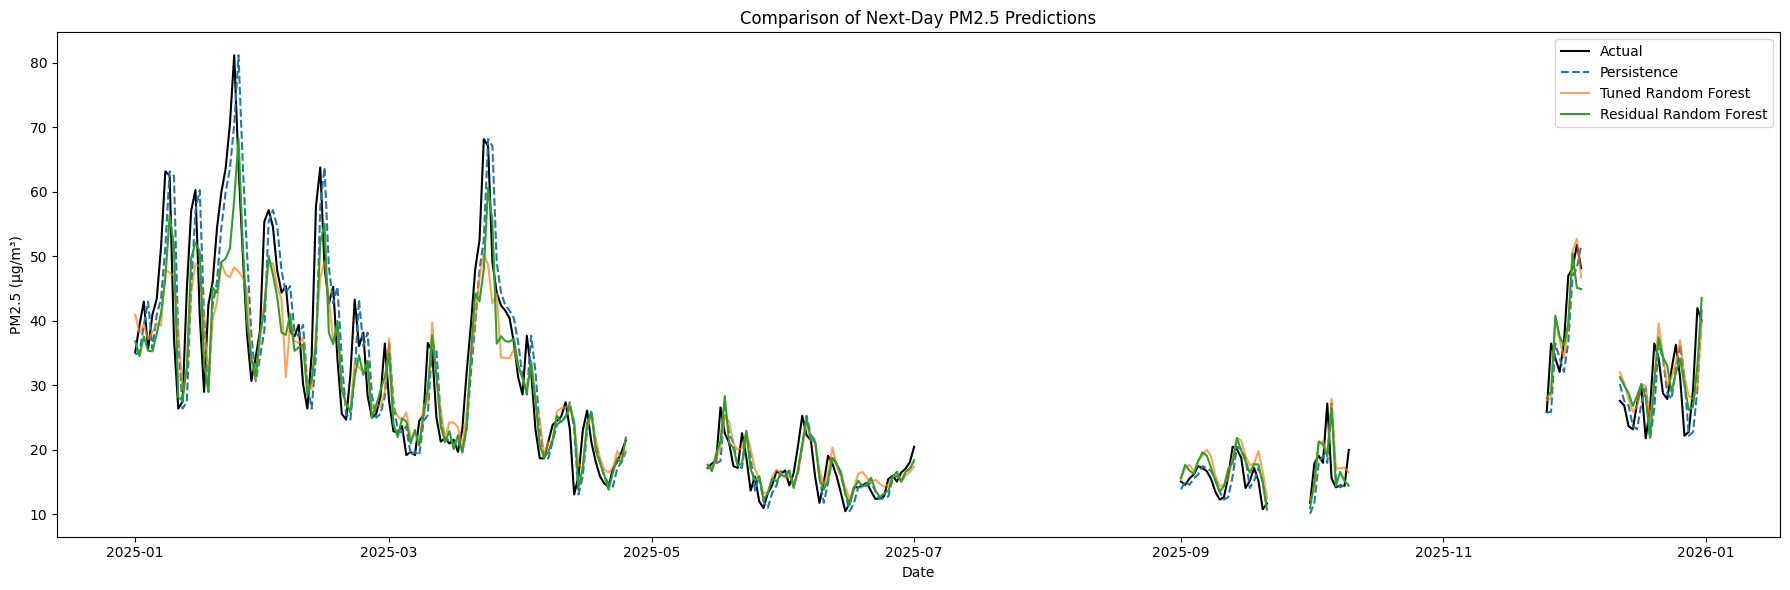

In [ ]:
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": today_val,
    "Tuned RF": tuned_val_pred,
    "Residual RF": residual_val_pred
}, index=pd.to_datetime(dates_val))

plot_df = plot_df.reindex(
    pd.date_range(
        "2025-01-01",
        "2025-12-31",
        freq="D"
    )
)

plt.figure(figsize=(18, 6))

plt.plot(
    plot_df["Actual"],
    color="black",
    label="Actual"
)

plt.plot(
    plot_df["Persistence"],
    linestyle="--",
    label="Persistence"
)

plt.plot(
    plot_df["Tuned RF"],
    alpha=0.7,
    label="Tuned Random Forest"
)

plt.plot(
    plot_df["Residual RF"],
    label="Residual Random Forest"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Comparison of Next-Day PM2.5 Predictions")
plt.legend()
plt.tight_layout()
plt.show()

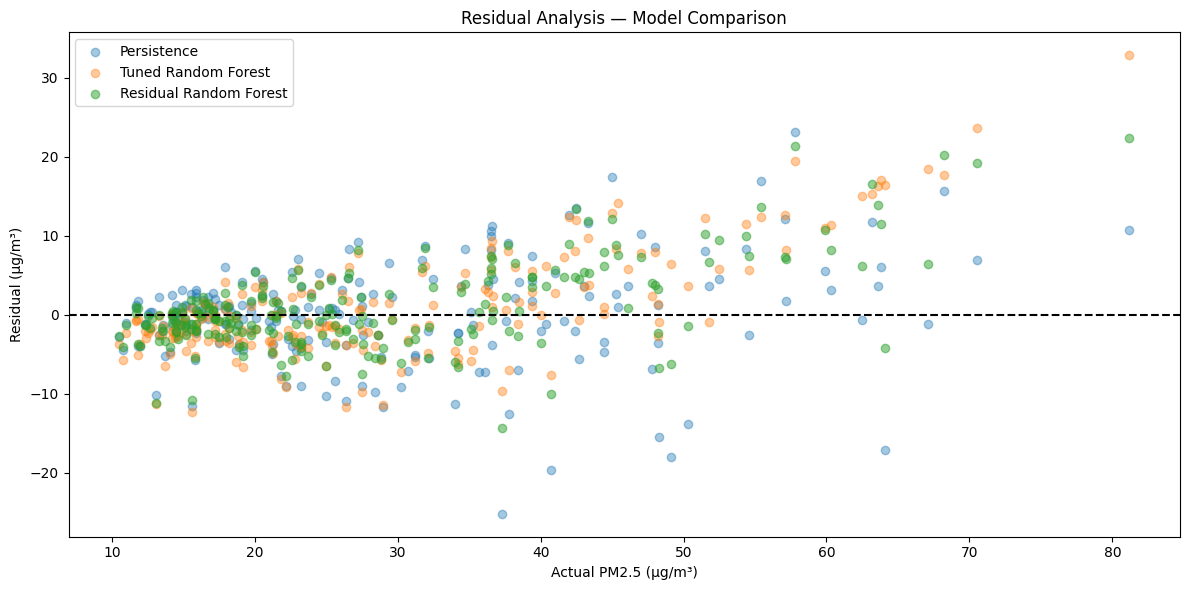

In [ ]:
persistence_errors = y_val - today_val
tuned_rf_errors = y_val - tuned_val_pred
residual_rf_errors = y_val - residual_val_pred

plt.figure(figsize=(12, 6))

plt.scatter(
    y_val,
    persistence_errors,
    alpha=0.4,
    label="Persistence"
)

plt.scatter(
    y_val,
    tuned_rf_errors,
    alpha=0.4,
    label="Tuned Random Forest"
)

plt.scatter(
    y_val,
    residual_rf_errors,
    alpha=0.5,
    label="Residual Random Forest"
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.title("Residual Analysis — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
error_df = pd.DataFrame({
    "actual": y_val,
    "persistence": today_val,
    "tuned_rf": tuned_val_pred,
    "residual_rf": residual_val_pred
})

error_df["pollution_level"] = pd.cut(
    error_df["actual"],
    bins=[0, 20, 35, 50, np.inf],
    labels=["0-20", "20-35", "35-50", "50+"],
    include_lowest=True
)

for model in ["persistence", "tuned_rf", "residual_rf"]:

    error_df[f"{model}_error"] = (
        error_df["actual"] - error_df[model]
    )

    error_df[f"{model}_abs_error"] = (
        error_df[f"{model}_error"].abs()
    )

summary = (
    error_df
    .groupby("pollution_level", observed=True)
    .agg(
        samples=("actual", "size"),
        persistence_MAE=("persistence_abs_error", "mean"),
        tuned_RF_MAE=("tuned_rf_abs_error", "mean"),
        residual_RF_MAE=("residual_rf_abs_error", "mean"),
        tuned_RF_bias=("tuned_rf_error", "mean"),
        residual_RF_bias=("residual_rf_error", "mean")
    )
)

print(summary.round(3))

                 samples  persistence_MAE  tuned_RF_MAE  residual_RF_MAE  \
pollution_level                                                            
0-20                  83            2.027         2.430            1.927   
20-35                 74            4.253         3.655            3.278   
35-50                 46            6.950         5.273            5.365   
50+                   21            8.433        13.706           11.153   

                 tuned_RF_bias  residual_RF_bias  
pollution_level                                   
0-20                    -1.936            -1.157  
20-35                   -1.551            -0.913  
35-50                    3.461             3.063  
50+                     13.615            10.627  


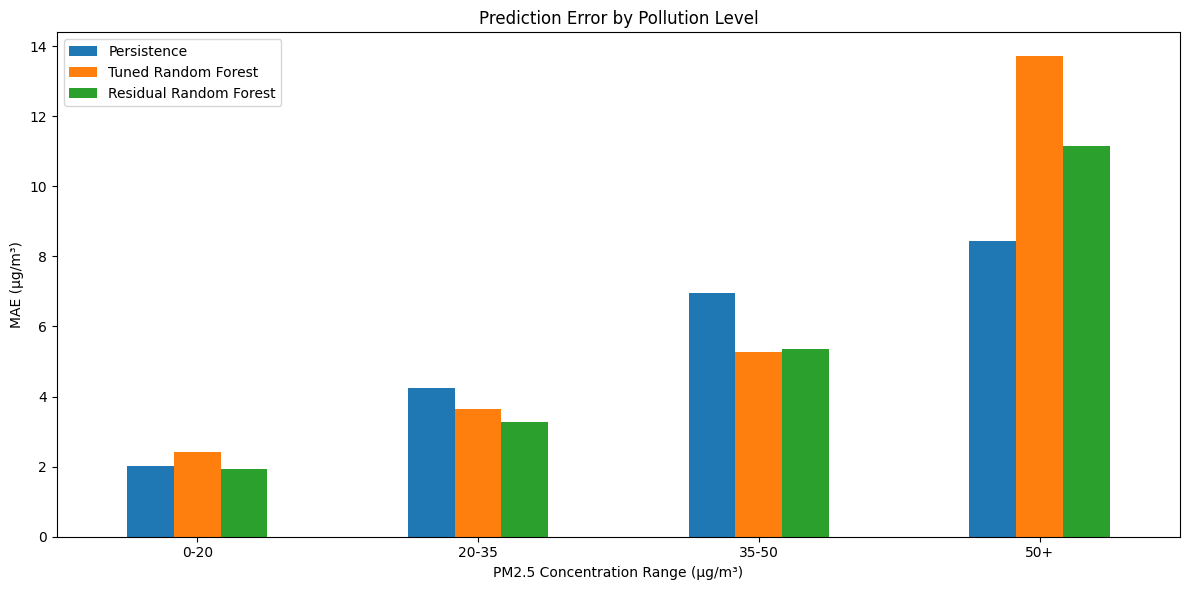

In [ ]:
summary[
    [
        "persistence_MAE",
        "tuned_RF_MAE",
        "residual_RF_MAE"
    ]
].plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

plt.xlabel("PM2.5 Concentration Range (µg/m³)")
plt.ylabel("MAE (µg/m³)")
plt.title("Prediction Error by Pollution Level")
plt.legend([
    "Persistence",
    "Tuned Random Forest",
    "Residual Random Forest"
])
plt.tight_layout()
plt.show()

In [ ]:
peak_index = np.argmax(y_val)

peak_comparison = pd.DataFrame({
    "Model": [
        "Actual",
        "Persistence",
        "Tuned Random Forest",
        "Residual Random Forest"
    ],
    "PM2.5": [
        y_val[peak_index],
        today_val[peak_index],
        tuned_val_pred[peak_index],
        residual_val_pred[peak_index]
    ]
})

print("Training maximum:", y_train.max())
print("Validation peak date:", dates_val[peak_index])
print(peak_comparison.round(3))

print(
    "Negative residual RF predictions:",
    (residual_val_pred < 0).sum()
)

Training maximum: 70.8
Validation peak date: 2025-01-24T00:00:00.000000000
                    Model   PM2.5
0                  Actual  81.200
1             Persistence  70.500
2     Tuned Random Forest  48.321
3  Residual Random Forest  58.781
Negative residual RF predictions: 0


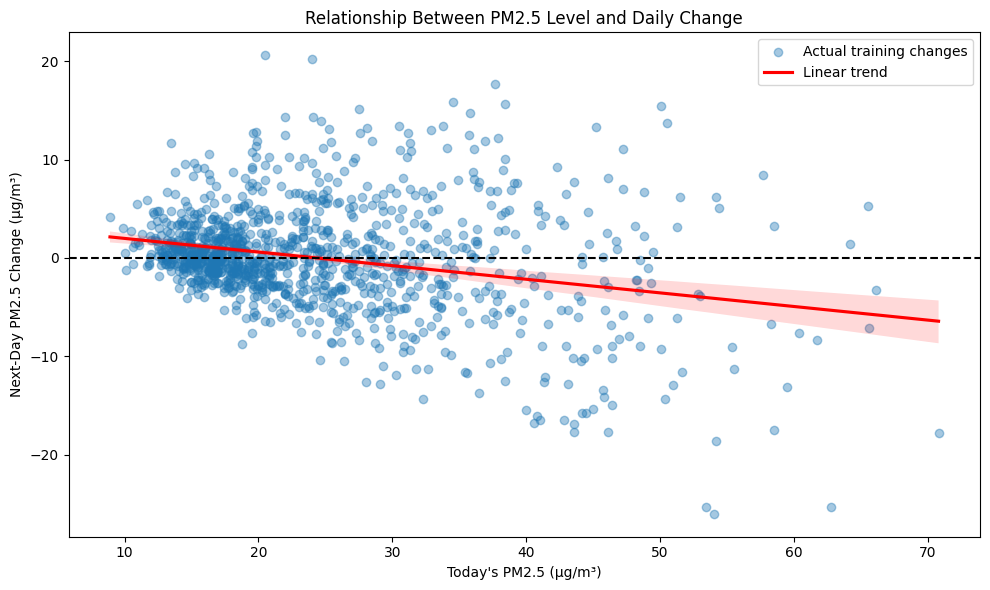

Correlation: -0.26513163609656737


In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    today_train,
    y_train_delta,
    alpha=0.4,
    label="Actual training changes"
)

sns.regplot(
    x=today_train,
    y=y_train_delta,
    scatter=False,
    color="red",
    label="Linear trend"
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Today's PM2.5 (µg/m³)")
plt.ylabel("Next-Day PM2.5 Change (µg/m³)")
plt.title("Relationship Between PM2.5 Level and Daily Change")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    np.corrcoef(today_train, y_train_delta)[0, 1]
)

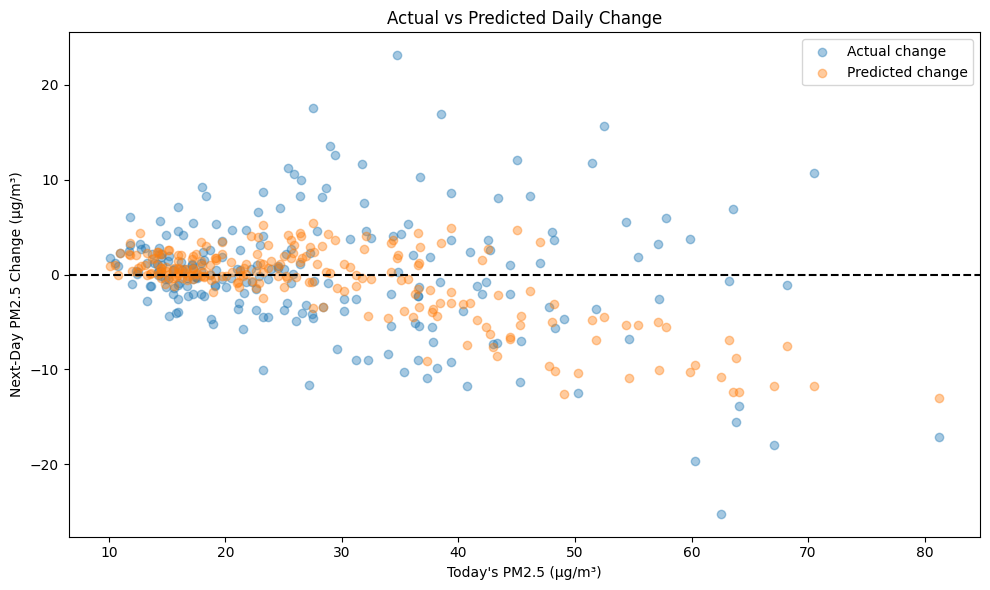

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    today_val,
    y_val - today_val,
    alpha=0.4,
    label="Actual change"
)

plt.scatter(
    today_val,
    residual_val_pred - today_val,
    alpha=0.4,
    label="Predicted change"
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Today's PM2.5 (µg/m³)")
plt.ylabel("Next-Day PM2.5 Change (µg/m³)")
plt.title("Actual vs Predicted Daily Change")
plt.legend()
plt.tight_layout()
plt.show()

Weighted residual learning

In [ ]:
alpha_results = []

delta_val_pred = residual_val_pred - today_val

for alpha in np.arange(0, 1.51, 0.05):

    weighted_pred = (
        today_val + alpha * delta_val_pred
    )

    metrics = evaluate_model(
        y_val,
        weighted_pred
    )

    alpha_results.append({
        "alpha": alpha,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "R2": metrics["R2"]
    })

alpha_results = pd.DataFrame(alpha_results)

print(alpha_results.round(4))

best_alpha = alpha_results.loc[
    alpha_results["RMSE"].idxmin()
]

print("\nBest configuration:")
print(best_alpha)

    alpha     MAE    RMSE      R2
0    0.00  4.3737  6.2417  0.8117
1    0.05  4.3090  6.1488  0.8173
2    0.10  4.2452  6.0609  0.8224
3    0.15  4.1855  5.9783  0.8272
4    0.20  4.1346  5.9013  0.8317
5    0.25  4.0846  5.8299  0.8357
6    0.30  4.0426  5.7644  0.8394
7    0.35  4.0062  5.7051  0.8427
8    0.40  3.9800  5.6521  0.8456
9    0.45  3.9572  5.6056  0.8481
10   0.50  3.9374  5.5658  0.8503
11   0.55  3.9202  5.5328  0.8520
12   0.60  3.9099  5.5067  0.8534
13   0.65  3.9025  5.4877  0.8544
14   0.70  3.8984  5.4757  0.8551
15   0.75  3.8971  5.4709  0.8553
16   0.80  3.8997  5.4733  0.8552
17   0.85  3.9070  5.4828  0.8547
18   0.90  3.9182  5.4995  0.8538
19   0.95  3.9296  5.5232  0.8525
20   1.00  3.9440  5.5539  0.8509
21   1.05  3.9615  5.5915  0.8489
22   1.10  3.9796  5.6357  0.8465
23   1.15  4.0038  5.6865  0.8437
24   1.20  4.0333  5.7437  0.8405
25   1.25  4.0723  5.8071  0.8370
26   1.30  4.1120  5.8765  0.8331
27   1.35  4.1574  5.9517  0.8288
28   1.40  4.2

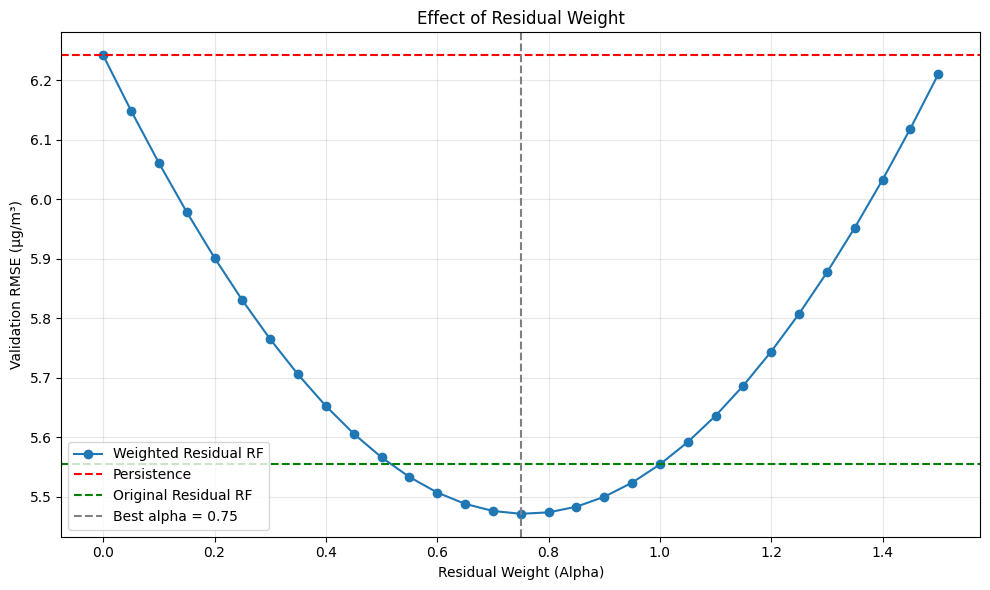

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    alpha_results["alpha"],
    alpha_results["RMSE"],
    marker="o",
    label="Weighted Residual RF"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence"
)

plt.axhline(
    5.5539,
    color="green",
    linestyle="--",
    label="Original Residual RF"
)

plt.axvline(
    best_alpha["alpha"],
    color="gray",
    linestyle="--",
    label=f'Best alpha = {best_alpha["alpha"]:.2f}'
)

plt.xlabel("Residual Weight (Alpha)")
plt.ylabel("Validation RMSE (µg/m³)")
plt.title("Effect of Residual Weight")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
actual_delta = y_val - today_val
predicted_delta = residual_val_pred - today_val

optimal_alpha = (
    np.sum(actual_delta * predicted_delta)
    / np.sum(predicted_delta ** 2)
)

weighted_val_pred = (
    today_val + optimal_alpha * predicted_delta
)

print("Optimal alpha:", optimal_alpha)

print(
    evaluate_model(y_val, weighted_val_pred)
)

Optimal alpha: 0.758431817277496
{'MAE': 3.897251811625632, 'RMSE': np.float64(5.470826146554376), 'R2': 0.8553341532002597}


In [ ]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100],
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_leaf": [1, 2, 4, 8, 16],
    "max_features": [0.5, 0.7, 1.0]
}

configurations = list(ParameterGrid(param_grid))

print("Total configurations:", len(configurations))

Total configurations: 90


In [ ]:
from tqdm.auto import tqdm
import time

residual_search_results = []

best_rmse = np.inf
best_residual_model = None
best_params = None

for params in tqdm(configurations):

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(
        X_train_flat,
        y_train_delta
    )

    elapsed = time.perf_counter() - start_time

    # Predict daily changes
    delta_train_pred = model.predict(X_train_flat)
    delta_val_pred = model.predict(X_val_flat)

    # Reconstruct absolute concentrations
    train_pred = today_train + delta_train_pred
    val_pred = today_val + delta_val_pred

    train_metrics = evaluate_model(y_train, train_pred)
    val_metrics = evaluate_model(y_val, val_pred)

    residual_search_results.append({
        **params,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

    if val_metrics["RMSE"] < best_rmse:

        best_rmse = val_metrics["RMSE"]
        best_residual_model = model
        best_params = params.copy()

residual_search_results = pd.DataFrame(
    residual_search_results
)

residual_search_results = (
    residual_search_results
    .sort_values("val_RMSE")
    .reset_index(drop=True)
)

print(residual_search_results.head(10).round(4))

print("\nBest parameters:", best_params)
print("Best RMSE:", best_rmse)

  0%|          | 0/90 [00:00<?, ?it/s]

   max_depth  max_features  min_samples_leaf  n_estimators  train_MAE  \
0        NaN           1.0                 2           100     1.3715   
1       15.0           1.0                 2           100     1.5316   
2       10.0           1.0                 2           100     1.9634   
3       10.0           1.0                 1           100     1.9568   
4       15.0           0.7                 2           100     1.5607   
5        NaN           0.5                 2           100     1.4140   
6       15.0           0.5                 2           100     1.5748   
7        7.0           1.0                 2           100     2.4878   
8       15.0           1.0                 4           100     1.8116   
9        NaN           0.7                 2           100     1.3861   

   train_RMSE  val_MAE  val_RMSE  val_R2  training_time  
0      2.0009   3.8559    5.4231  0.8578         2.7583  
1      2.1098   3.8783    5.4328  0.8573         2.0084  
2      2.5904   3.8527

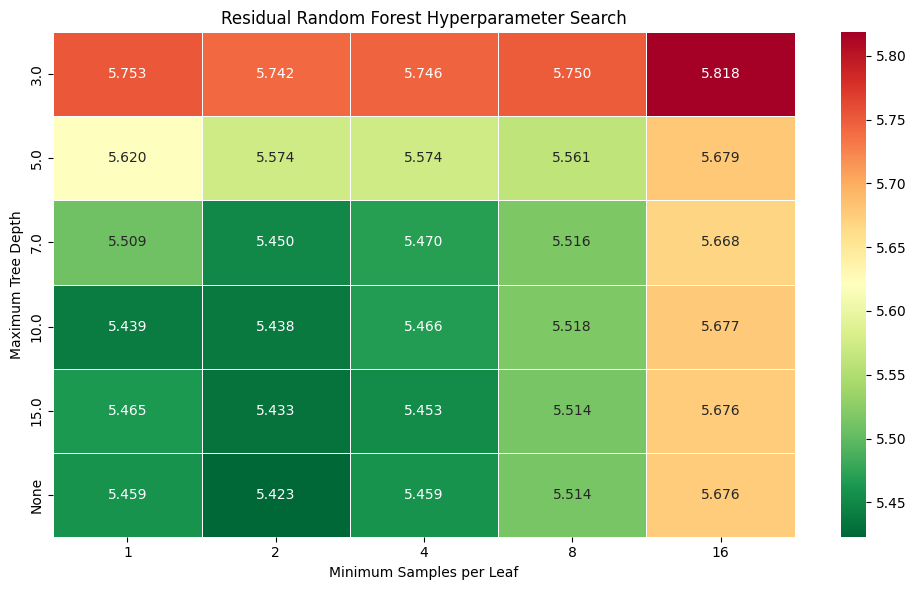

In [ ]:
heatmap_df = residual_search_results.copy()

heatmap_df["max_depth"] = (
    heatmap_df["max_depth"]
    .fillna("None")
    .astype(str)
)

heatmap_data = heatmap_df.pivot_table(
    index="max_depth",
    columns="min_samples_leaf",
    values="val_RMSE",
    aggfunc="min"
)

heatmap_data = heatmap_data.reindex(
    ["3.0", "5.0", "7.0", "10.0", "15.0", "None"]
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("Maximum Tree Depth")
plt.title("Residual Random Forest Hyperparameter Search")
plt.tight_layout()
plt.show()

In [ ]:
best_delta_val_pred = best_residual_model.predict(
    X_val_flat
)

actual_delta = y_val - today_val

denominator = np.sum(best_delta_val_pred ** 2)

if denominator > 0:

    best_alpha = (
        np.sum(actual_delta * best_delta_val_pred)
        / denominator
    )

else:
    best_alpha = 0.0

best_weighted_val_pred = (
    today_val + best_alpha * best_delta_val_pred
)

print("Best parameters:", best_params)
print("Optimal alpha:", best_alpha)

print(
    evaluate_model(
        y_val,
        best_weighted_val_pred
    )
)

Best parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 100}
Optimal alpha: 0.8489355303805685
{'MAE': 3.8372088886610496, 'RMSE': np.float64(5.394219369365096), 'R2': 0.8593572356017302}


In [ ]:
output = (
    PROJECT_DIR
    / "experiments/residual_rf_grid_search.csv"
)

output.parent.mkdir(
    parents=True,
    exist_ok=True
)

residual_search_results.to_csv(
    output,
    index=False
)

print("Results saved:", output)

Results saved: /content/drive/MyDrive/PM25_Prediction/experiments/residual_rf_grid_search.csv


In [ ]:
import joblib

model_bundle = {
    "model": best_residual_model,
    "alpha": float(best_alpha),
    "features": FEATURES,
    "window_size": WINDOW_SIZE,
    "target_type": "delta",
    "hyperparameters": best_params
}

joblib.dump(
    model_bundle,
    PROJECT_DIR / "models/random_forest_residual_tuned.joblib"
)

['/content/drive/MyDrive/PM25_Prediction/models/random_forest_residual_tuned.joblib']

In [ ]:
import joblib

model_bundle = {
    "model_name": "Optimized Weighted Residual Random Forest",

    "model": best_residual_model,

    "alpha": float(best_alpha),

    "features": FEATURES,

    "window_size": X_train.shape[1],

    "target_type": "delta",

    "hyperparameters": best_params,

    "validation_metrics": evaluate_model(
        y_val,
        best_weighted_val_pred
    )
}

output = (
    PROJECT_DIR
    / "models/random_forest_final.joblib"
)

output.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(model_bundle, output)

print("Final model saved:", output)

Final model saved: /content/drive/MyDrive/PM25_Prediction/models/random_forest_final.joblib


                 Persistence_MAE  Tuned RF_MAE  Residual RF_MAE  Final RF_MAE
Pollution Range                                                              
0-20                      2.0265        2.4302           1.9266        1.9304
20-35                     4.2527        3.6547           3.2778        3.1608
35-50                     6.9500        5.2730           5.3649        5.5030
50+                       8.4333       13.7056          11.1529       10.1085

Samples per range:
Pollution Range
0-20     83
20-35    74
35-50    46
50+      21
dtype: int64


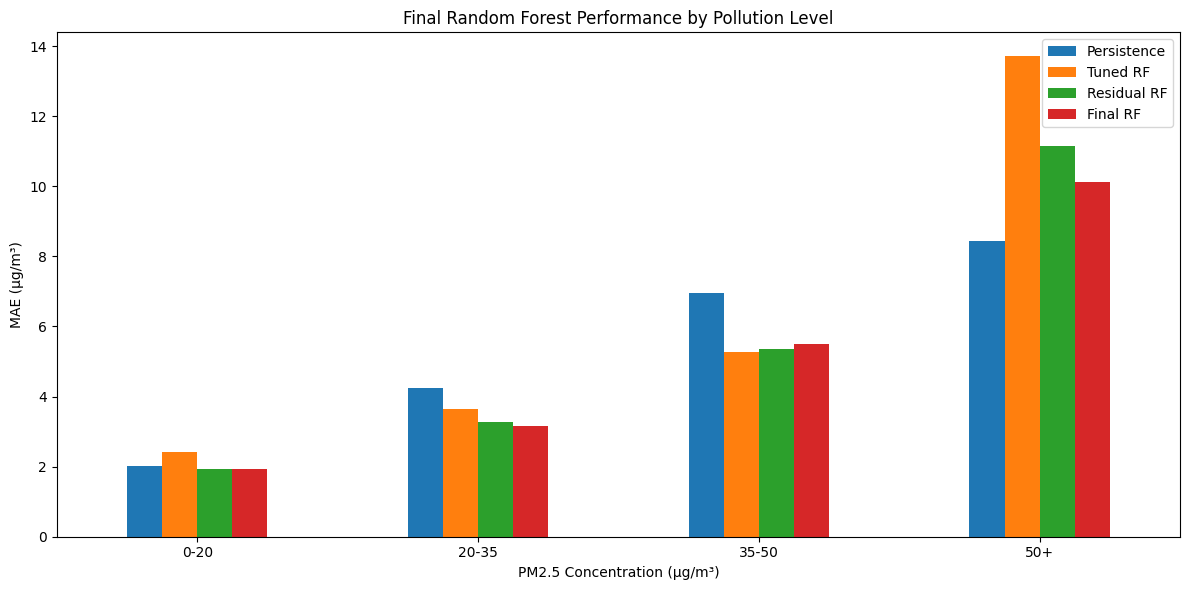

In [ ]:
final_error_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": today_val,
    "Tuned RF": tuned_val_pred,
    "Residual RF": residual_val_pred,
    "Final RF": final_val_pred
})

final_error_df["Pollution Range"] = pd.cut(
    final_error_df["Actual"],
    bins=[0, 20, 35, 50, np.inf],
    labels=["0-20", "20-35", "35-50", "50+"],
    include_lowest=True
)

models = [
    "Persistence",
    "Tuned RF",
    "Residual RF",
    "Final RF"
]

for name in models:
    final_error_df[name + "_MAE"] = (
        final_error_df["Actual"]
        - final_error_df[name]
    ).abs()

final_summary = (
    final_error_df
    .groupby("Pollution Range", observed=True)
    [[name + "_MAE" for name in models]]
    .mean()
)

print(final_summary.round(4))

print("\nSamples per range:")
print(
    final_error_df.groupby(
        "Pollution Range", observed=True
    ).size()
)

final_summary.columns = models

final_summary.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("MAE (µg/m³)")
plt.title("Final Random Forest Performance by Pollution Level")
plt.tight_layout()
plt.show()